Link: https://youtu.be/VVmgd5OzDuY

# Actividad - Proyecto final

**Mateo Bermejo**

**Asignatura:** Big Data

**Herramientas:** Pipeline integral de Big Data con Machine Learning, almacenamiento
híbrido y dashboard contenerizado

## Objetivo

Construir, sobre un dataset real de gran volumen, un pipeline completo de Big Data que integre lo trabajado
durante el curso (ETL con CRISP-DM, procesamiento con pandas o Spark, almacenamiento híbrido,
visualización y análisis multidimensional) y lo extienda con un modelo de Machine Learning, entregando los
resultados en un dashboard web y un reporte PDF, con toda la solución ejecutándose en contenedores
Docker

In [1]:

import pandas as pd
import os

# ==========================================
# 1. RUTA DEL ARCHIVO CSV
# ==========================================

ruta = r"../Data3/Connacionales_inscritos_en_el_Registro_Ciudadano_en_Línea_20261117.csv"

# ==========================================
# 2. VERIFICAR ARCHIVO
# ==========================================

if os.path.exists(ruta):

    print("Archivo encontrado correctamente.")

    # ==========================================
    # 3. TAMAÑO DEL ARCHIVO
    # ==========================================

    tamaño_mb = os.path.getsize(ruta) / (1024 ** 2)
    print(f"\nTamaño: {tamaño_mb:.2f} MB")

    # ==========================================
    # 4. CARGAR CSV
    # ==========================================

    df = pd.read_csv(ruta, encoding="utf-8-sig", low_memory=False)

    # ==========================================
    # 5. INFORMACIÓN GENERAL
    # ==========================================

    print(f"\nCantidad de registros: {len(df):,}")
    print(f"Cantidad de columnas: {len(df.columns)}")

    # ==========================================
    # 6. PRIMEROS CINCO REGISTROS
    # ==========================================

    print("\nPrimeros cinco registros:")
    display(df.head())

    # ==========================================
    # 7. INFORMACIÓN DE COLUMNAS
    # ==========================================

    print("\nInformación general:")
    df.info()

else:
    print("No se encontró el archivo. Verifica la ruta.")


Archivo encontrado correctamente.

Tamaño: 120.59 MB

Cantidad de registros: 639,041
Cantidad de columnas: 14

Primeros cinco registros:


,País,Código ISO país,Ciudad de Residencia,Oficina de circunscripción consular,Edad (años),Área Conocimiento,Nivel Académico,Estado civil,Sexo,Pertenencia étnica,Ciudad de Nacimiento,Localización,Fecha de Registro,Cantidad de personas
0,AFGANISTAN,AFG,BADAKHSHAN/BUCHI,C. NUEVA DELHI,37,"ECONOMÍA, ADMINISTRACIÓN CONTADURIA Y AFINES",SIN INFORMACIÓN,DESCONOCIDO,FEMENINO,OTRO,COLOMBIA/SANTANDER/BUCARAMANGA,"(33.93911, 67.709953)",2018-10,1
1,ALBANIA,ALB,VLORE/ARMENI,C. ROMA,32,CIENCIAS DE LA EDUCACIÓN,SIN INFORMACIÓN,DESCONOCIDO,MASCULINO,OTRO,COLOMBIA/QUINDIO/ARMENIA,"(41.153332, 20.168331)",2018-12,1
2,ALBANIA,ALB,VLORE/VLORE,C. ROMA,39,NINGUNA,BACHILLERATO,CASADO,MASCULINO,NINGUNA,VENEZUELA/CARABOBO/VALENCIA,"(41.153332, 20.168331)",2014-08,1
3,ALEMANIA,DEU,BERLIN/BERLIN,C. BERLIN,25,CIENCIAS SOCIALES Y HUMANAS,SIN INFORMACIÓN,SOLTERO,FEMENINO,OTRO,COLOMBIA/CUNDINAMARCA/BOGOTA,"(51.165691, 10.451526)",2021-11,1
4,ALEMANIA,DEU,BERLIN/BERLIN,C. BERLIN,25,"CIENCIAS SOCIALES, PERIODISMO E INFORMACIÓN",MAESTRÍA,CASADO,FEMENINO,NINGUNA,(NO REGISTRA),"(51.165691, 10.451526)",2025-11,1



Información general:
<class 'pandas.DataFrame'>
RangeIndex: 639041 entries, 0 to 639040
Data columns (total 14 columns):
 #   Column                               Non-Null Count   Dtype
---  ------                               --------------   -----
 0   País                                 639041 non-null  str  
 1   Código ISO país                      639041 non-null  str  
 2   Ciudad de Residencia                 639041 non-null  str  
 3   Oficina de circunscripción consular  639041 non-null  str  
 4   Edad (años)                          639041 non-null  int64
 5   Área Conocimiento                    639041 non-null  str  
 6   Nivel Académico                      639041 non-null  str  
 7   Estado civil                         639041 non-null  str  
 8   Sexo                                 639041 non-null  str  
 9   Pertenencia étnica                   639041 non-null  str  
 10  Ciudad de Nacimiento                 639041 non-null  str  
 11  Localización                

## Validación de datos

In [2]:

# ==========================================
# DIAGNÓSTICO INICIAL DE CALIDAD
# ==========================================

# 1. Valores faltantes por columna
print("VALORES FALTANTES:")
display(df.isnull().sum())

# 2. Registros duplicados
duplicados = df.duplicated().sum()

print("\nREGISTROS DUPLICADOS:")
print(f"Total: {duplicados:,}")

# 3. Valores únicos por columna
print("\nVALORES ÚNICOS:")
display(df.nunique())

# 4. Estadísticas descriptivas
print("\nESTADÍSTICAS DESCRIPTIVAS:")
display(df.describe(include="all").T)

# 5. Revisar las primeras fechas
print("\nFECHAS DE REGISTRO:")
display(df["Fecha de Registro"].head(10))

# 6. Revisar cantidad de personas
print("\nCANTIDAD DE PERSONAS:")
display(df["Cantidad de personas"].describe())


VALORES FALTANTES:


País                                   0
Código ISO país                        0
Ciudad de Residencia                   0
Oficina de circunscripción consular    0
Edad (años)                            0
Área Conocimiento                      0
Nivel Académico                        0
Estado civil                           0
Sexo                                   0
Pertenencia étnica                     0
Ciudad de Nacimiento                   0
Localización                           6
Fecha de Registro                      0
Cantidad de personas                   0
dtype: int64


REGISTROS DUPLICADOS:
Total: 0

VALORES ÚNICOS:


País                                     167
Código ISO país                          164
Ciudad de Residencia                   26075
Oficina de circunscripción consular      114
Edad (años)                               16
Área Conocimiento                         25
Nivel Académico                           12
Estado civil                               8
Sexo                                       4
Pertenencia étnica                         8
Ciudad de Nacimiento                    5596
Localización                             161
Fecha de Registro                        166
Cantidad de personas                       6
dtype: int64


ESTADÍSTICAS DESCRIPTIVAS:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
País,639041,167,ESPAÑA,210497,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Código ISO país,639041,164,ESP,210497,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ciudad de Residencia,639041,26075,MADRID/MADRID,36077,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Oficina de circunscripción consular,639041,114,C. MADRID,75199,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Edad (años),639041.0,NaN,NaN,NaN,33.233609,4.311984,25.0,30.0,33.0,37.0,40.0
Área Conocimiento,639041,25,NINGUNA,305975,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nivel Académico,639041,12,SIN INFORMACIÓN,208932,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Estado civil,639041,8,SOLTERO,406164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sexo,639041,4,FEMENINO,334049,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pertenencia étnica,639041,8,OTRO,337036,NaN,NaN,NaN,NaN,NaN,NaN,NaN



FECHAS DE REGISTRO:


0    2018-10
1    2018-12
2    2014-08
3    2021-11
4    2025-11
5    2025-07
6    2019-01
7    2018-11
8    2019-01
9    2024-05
Name: Fecha de Registro, dtype: str


CANTIDAD DE PERSONAS:


count    639041.00000
mean          1.00618
std           0.08551
min           1.00000
25%           1.00000
50%           1.00000
75%           1.00000
max           7.00000
Name: Cantidad de personas, dtype: float64

In [3]:
# REVISIÓN DE CATEGORÍAS Y VALORES ESPECIALES

columnas = [
    "Sexo",
    "Estado civil",
    "Área Conocimiento",
    "Nivel Académico",
    "Pertenencia étnica"
]

for columna in columnas:
    print(f"\n--- {columna} ---")
    display(df[columna].value_counts(dropna=False))

print("\n--- CANTIDAD DE PERSONAS ---")
display(df["Cantidad de personas"].value_counts().sort_index())

print("\n--- REGISTROS CON MÁS DE UNA PERSONA ---")
display(
    df[df["Cantidad de personas"] > 1]
)

print("\n--- RANGO DE FECHAS ---")
print("Fecha inicial:", df["Fecha de Registro"].min())
print("Fecha final:", df["Fecha de Registro"].max())


--- Sexo ---


Sexo
FEMENINO       334049
MASCULINO      304788
DESCONOCIDO       195
NO_BINARIO          9
Name: count, dtype: int64


--- Estado civil ---


Estado civil
SOLTERO                 406164
CASADO                  116735
UNION_LIBRE              67358
DESCONOCIDO              38535
DIVORCIADO                7654
SEPARADO_UNION_LIBRE       924
SEPARADO_MATRIMONIO        892
VIUDO                      779
Name: count, dtype: int64


--- Área Conocimiento ---


Área Conocimiento
NINGUNA                                                  305975
ECONOMÍA, ADMINISTRACIÓN CONTADURIA Y AFINES              57168
INGENIERÍA, ARQUITECTURA Y AFINES                         46704
NO INDICA                                                 37657
CIENCIAS DE LA SALUD                                      31737
CIENCIAS SOCIALES Y HUMANAS                               31555
ADMINISTRACIÓN DE EMPRESAS Y DERECHO                      25290
INGENIERÍA, INDUSTRIA Y CONSTRUCCIÓN                      18900
BELLAS ARTES                                              15350
SALUD Y BIENESTAR                                         14788
CIENCIAS SOCIALES, PERIODISMO E INFORMACIÓN                9800
CIENCIAS DE LA EDUCACIÓN                                   9468
ARTES Y HUMANIDADES                                        6037
MATEMÁTICAS Y CIENCIAS NATURALES                           5582
EDUCACIÓN                                                  4993
CIENCIAS NATURALES, MA

... (5 outputs left out)

Cantidad de personas
1    635389
2      3415
3       191
4        34
5        11
7         1
Name: count, dtype: int64


--- REGISTROS CON MÁS DE UNA PERSONA ---


,País,Código ISO país,Ciudad de Residencia,Oficina de circunscripción consular,Edad (años),Área Conocimiento,Nivel Académico,Estado civil,Sexo,Pertenencia étnica,Ciudad de Nacimiento,Localización,Fecha de Registro,Cantidad de personas
1471,ANDORRA,AND,ANDORRA LA VELLA/ANDORRA,C. BARCELONA,37,NINGUNA,BACHILLERATO,SOLTERO,MASCULINO,OTRO,COLOMBIA/ANTIOQUIA/MEDELLIN,"(42.546245, 1.601554)",2016-01,2
2199,ARGENTINA,ARG,BUENOS AIRES/CAPITAL FEDERAL,C. BUENOS AIRES,29,NO INDICA,BACHILLERATO,SOLTERO,MASCULINO,NINGUNA,COLOMBIA/CUNDINAMARCA/BOGOTA,"(-38.416097, -63.616672)",2015-09,2
2962,ARGENTINA,ARG,CHACO/RESISTENCIA,C. BUENOS AIRES,40,NINGUNA,BACHILLERATO,UNION_LIBRE,MASCULINO,NINGUNA,COLOMBIA/CALDAS/SUPIA,"(-38.416097, -63.616672)",2023-07,2
3106,ARGENTINA,ARG,DISTRITO FEDERAL/BUENOS AIRES,C. BUENOS AIRES,27,NINGUNA,SIN INFORMACIÓN,SOLTERO,MASCULINO,OTRO,COLOMBIA/CUNDINAMARCA/BOGOTA,"(-38.416097, -63.616672)",2017-06,2
3154,ARGENTINA,ARG,DISTRITO FEDERAL/BUENOS AIRES,C. BUENOS AIRES,29,NINGUNA,SIN INFORMACIÓN,SOLTERO,FEMENINO,OTRO,COLOMBIA/CUNDINAMARCA/BOGOTA,"(-38.416097, -63.616672)",2017-07,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
638241,ECUADOR,ECU,GUAYAS/GUAYAQUIL,C. GUAYAQUIL,27,NINGUNA,SIN INFORMACIÓN,SOLTERO,MASCULINO,NINGUNA,COLOMBIA/RISARALDA/PEREIRA,"(-1.831239, -78.183406)",2018-02,2
638306,ESPAÑA,ESP,MADRID/MADRID,C. MADRID,27,NINGUNA,SIN INFORMACIÓN,SOLTERO,FEMENINO,OTRO,COLOMBIA/VALLE DEL CAUCA/CALI,"(40.463667, -3.74922)",2017-05,2
638561,ESTADOS UNIDOS,USA,NEW JERSEY/RANDOLPH,C. NEWARK,26,NINGUNA,SIN INFORMACIÓN,SOLTERO,FEMENINO,NINGUNA,ESTADOS UNIDOS/NEW JERSEY/MORRISTOWN,"(37.09024, -95.712891)",2020-02,2
638679,ESPAÑA,ESP,VIZCAYA/BILBAO,C. BILBAO,37,NO INDICA,BACHILLERATO,SOLTERO,FEMENINO,SIN ETNIA REGISTRADA,COLOMBIA/ANTIOQUIA/MEDELLIN,"(40.463667, -3.74922)",2015-10,2



--- RANGO DE FECHAS ---
Fecha inicial: 1900-01
Fecha final: 2026-10


## Revisión de las fechas y los registros agrupados

In [4]:
# ANÁLISIS TEMPORAL Y REGISTROS AGRUPADOS

print("RANGO DE FECHAS")
print("Fecha inicial:", df["Fecha de Registro"].min())
print("Fecha final:", df["Fecha de Registro"].max())

print("\nREGISTROS CON MÁS DE UNA PERSONA")
df_agrupados = df[df["Cantidad de personas"] > 1]

print("Cantidad de registros:", len(df_agrupados))
print("Total de personas en esos registros:",
      df_agrupados["Cantidad de personas"].sum())

display(df_agrupados.head(10))

print("\nDISTRIBUCIÓN DE REGISTROS POR AÑO")
fechas = pd.to_datetime(df["Fecha de Registro"], format="%Y-%m")
display(fechas.dt.year.value_counts().sort_index())

RANGO DE FECHAS
Fecha inicial: 1900-01
Fecha final: 2026-10

REGISTROS CON MÁS DE UNA PERSONA
Cantidad de registros: 3652
Total de personas en esos registros: 7601


,País,Código ISO país,Ciudad de Residencia,Oficina de circunscripción consular,Edad (años),Área Conocimiento,Nivel Académico,Estado civil,Sexo,Pertenencia étnica,Ciudad de Nacimiento,Localización,Fecha de Registro,Cantidad de personas
1471,ANDORRA,AND,ANDORRA LA VELLA/ANDORRA,C. BARCELONA,37,NINGUNA,BACHILLERATO,SOLTERO,MASCULINO,OTRO,COLOMBIA/ANTIOQUIA/MEDELLIN,"(42.546245, 1.601554)",2016-01,2
2199,ARGENTINA,ARG,BUENOS AIRES/CAPITAL FEDERAL,C. BUENOS AIRES,29,NO INDICA,BACHILLERATO,SOLTERO,MASCULINO,NINGUNA,COLOMBIA/CUNDINAMARCA/BOGOTA,"(-38.416097, -63.616672)",2015-09,2
2962,ARGENTINA,ARG,CHACO/RESISTENCIA,C. BUENOS AIRES,40,NINGUNA,BACHILLERATO,UNION_LIBRE,MASCULINO,NINGUNA,COLOMBIA/CALDAS/SUPIA,"(-38.416097, -63.616672)",2023-07,2
3106,ARGENTINA,ARG,DISTRITO FEDERAL/BUENOS AIRES,C. BUENOS AIRES,27,NINGUNA,SIN INFORMACIÓN,SOLTERO,MASCULINO,OTRO,COLOMBIA/CUNDINAMARCA/BOGOTA,"(-38.416097, -63.616672)",2017-06,2
3154,ARGENTINA,ARG,DISTRITO FEDERAL/BUENOS AIRES,C. BUENOS AIRES,29,NINGUNA,SIN INFORMACIÓN,SOLTERO,FEMENINO,OTRO,COLOMBIA/CUNDINAMARCA/BOGOTA,"(-38.416097, -63.616672)",2017-07,3
3170,ARGENTINA,ARG,DISTRITO FEDERAL/BUENOS AIRES,C. BUENOS AIRES,29,NO INDICA,BACHILLERATO,SOLTERO,MASCULINO,SIN ETNIA REGISTRADA,COLOMBIA/CUNDINAMARCA/BOGOTA,"(-38.416097, -63.616672)",2014-01,3
3208,ARGENTINA,ARG,DISTRITO FEDERAL/BUENOS AIRES,C. BUENOS AIRES,30,NINGUNA,SIN INFORMACIÓN,SOLTERO,FEMENINO,OTRO,COLOMBIA/VALLE DEL CAUCA/CALI,"(-38.416097, -63.616672)",2017-06,2
3265,ARGENTINA,ARG,DISTRITO FEDERAL/BUENOS AIRES,C. BUENOS AIRES,31,NINGUNA,SIN INFORMACIÓN,SOLTERO,FEMENINO,OTRO,COLOMBIA/CUNDINAMARCA/BOGOTA,"(-38.416097, -63.616672)",2017-05,3
3319,ARGENTINA,ARG,DISTRITO FEDERAL/BUENOS AIRES,C. BUENOS AIRES,32,NO INDICA,BACHILLERATO,SOLTERO,MASCULINO,NINGUNA,COLOMBIA/CUNDINAMARCA/BOGOTA,"(-38.416097, -63.616672)",2014-03,2
3382,ARGENTINA,ARG,DISTRITO FEDERAL/BUENOS AIRES,C. BUENOS AIRES,33,NO INDICA,BACHILLERATO,SOLTERO,MASCULINO,NINGUNA,COLOMBIA/CUNDINAMARCA/BOGOTA,"(-38.416097, -63.616672)",2014-03,2



DISTRIBUCIÓN DE REGISTROS POR AÑO


Fecha de Registro
1900      156
2013     9661
2014    19686
2015    27969
2016    26033
2017    32519
2018    37166
2019    37775
2020    26727
2021    41869
2022    68602
2023    82931
2024    80209
2025    91851
2026    55887
Name: count, dtype: int64

## Investigación fechas atípicas (1900)

In [5]:
# INVESTIGACIÓN DE FECHAS ATÍPICAS

df["Año_Registro"] = pd.to_datetime(
    df["Fecha de Registro"],
    format="%Y-%m"
).dt.year

print("REGISTROS POR AÑO:")
display(df["Año_Registro"].value_counts().sort_index())

print("\nREGISTROS DEL AÑO 1900:")
display(
    df[df["Año_Registro"] == 1900].head(20)
)

print("\nCANTIDAD DE REGISTROS DEL AÑO 1900:")
print((df["Año_Registro"] == 1900).sum())

REGISTROS POR AÑO:


Año_Registro
1900      156
2013     9661
2014    19686
2015    27969
2016    26033
2017    32519
2018    37166
2019    37775
2020    26727
2021    41869
2022    68602
2023    82931
2024    80209
2025    91851
2026    55887
Name: count, dtype: int64


REGISTROS DEL AÑO 1900:


,País,Código ISO país,Ciudad de Residencia,Oficina de circunscripción consular,Edad (años),Área Conocimiento,Nivel Académico,Estado civil,Sexo,Pertenencia étnica,Ciudad de Nacimiento,Localización,Fecha de Registro,Cantidad de personas,Año_Registro
1624,ARGENTINA,ARG,BUENOS AIRES/BUENOS AIRES,C. BUENOS AIRES,33,NINGUNA,BACHILLERATO,DESCONOCIDO,MASCULINO,NINGUNA,COLOMBIA/CAQUETA/FLORENCIA,"(-38.416097, -63.616672)",1900-01,1,1900
1803,ARGENTINA,ARG,"BUENOS AIRES/BUENOS AIRES, CAPITAL FEDERAL",C. BUENOS AIRES,30,CIENCIAS SOCIALES Y HUMANAS,PROFESIONAL,DESCONOCIDO,FEMENINO,OTRO,(NO REGISTRA),"(-38.416097, -63.616672)",1900-01,1,1900
4498,ARUBA,ABW,ARUBA/ARUBA,C. ARUBA,34,NINGUNA,BACHILLERATO,CASADO,FEMENINO,NINGUNA,COLOMBIA/ATLANTICO/BARANOA,"(12.52111, -69.968338)",1900-01,1,1900
12520,CANADA,CAN,ONTARIO/TORONTO,C. TORONTO,36,CIENCIAS DE LA SALUD,PROFESIONAL,SOLTERO,FEMENINO,OTRO,COLOMBIA/BOYACA/DUITAMA,"(56.130366, -106.346771)",1900-01,1,1900
15433,CHILE,CHL,REGION METROPOLITANA/SANTIAGO,C. SANTIAGO,38,NINGUNA,BACHILLERATO,DESCONOCIDO,FEMENINO,OTRO,(NO REGISTRA),"(-35.675147, -71.542969)",1900-01,1,1900
16687,COSTA RICA,CRI,HEREDIA/HEREDIA,C. SAN JOSE,32,COCINA Y CULINARIA,PROFESIONAL,VIUDO,FEMENINO,NINGUNA,COLOMBIA/ANTIOQUIA/MEDELLIN,"(9.748917, -83.753428)",1900-01,1,1900
19442,ECUADOR,ECU,GUAYAS/SANTA ELENA,C. GUAYAQUIL,28,NINGUNA,PRIMARIA,UNION_LIBRE,FEMENINO,OTRO,COLOMBIA/VALLE DEL CAUCA/EL CERRITO,"(-1.831239, -78.183406)",1900-01,1,1900
26954,ESPAÑA,ESP,CATALUÑA/MATARO,C. BARCELONA,30,NINGUNA,BACHILLERATO,UNION_LIBRE,MASCULINO,NINGUNA,COLOMBIA/HUILA/NEIVA,"(40.463667, -3.74922)",1900-01,1,1900
53158,ESTADOS UNIDOS,USA,TENNESSEE/NASHVILLE,C. ATLANTA,40,NINGUNA,BACHILLERATO,CASADO,FEMENINO,NINGUNA,COLOMBIA/ANTIOQUIA/MEDELLIN,"(37.09024, -95.712891)",1900-01,1,1900
53711,ESTADOS UNIDOS,USA,MASSACHUSETTS/EVERETT,C. BOSTON,26,NINGUNA,BACHILLERATO,SOLTERO,MASCULINO,OTRO,COLOMBIA/ANTIOQUIA/SAN PEDRO,"(37.09024, -95.712891)",1900-01,1,1900



CANTIDAD DE REGISTROS DEL AÑO 1900:
156


In [6]:
# REVISIÓN DE REGISTROS DE 1900

display(
    df[df["Año_Registro"] == 1900][
        ["País", "Ciudad de Residencia",
         "Fecha de Registro", "Cantidad de personas"]
    ].head(20)
)

print("Cantidad de registros de 1900:",
      (df["Año_Registro"] == 1900).sum())

print("\nTOTAL DE REGISTROS:", len(df))

print("TOTAL DE PERSONAS REPRESENTADAS:",
      df["Cantidad de personas"].sum())

,País,Ciudad de Residencia,Fecha de Registro,Cantidad de personas
1624,ARGENTINA,BUENOS AIRES/BUENOS AIRES,1900-01,1
1803,ARGENTINA,"BUENOS AIRES/BUENOS AIRES, CAPITAL FEDERAL",1900-01,1
4498,ARUBA,ARUBA/ARUBA,1900-01,1
12520,CANADA,ONTARIO/TORONTO,1900-01,1
15433,CHILE,REGION METROPOLITANA/SANTIAGO,1900-01,1
16687,COSTA RICA,HEREDIA/HEREDIA,1900-01,1
19442,ECUADOR,GUAYAS/SANTA ELENA,1900-01,1
26954,ESPAÑA,CATALUÑA/MATARO,1900-01,1
53158,ESTADOS UNIDOS,TENNESSEE/NASHVILLE,1900-01,1
53711,ESTADOS UNIDOS,MASSACHUSETTS/EVERETT,1900-01,1


Cantidad de registros de 1900: 156

TOTAL DE REGISTROS: 639041
TOTAL DE PERSONAS REPRESENTADAS: 642990


In [7]:
# REVISIÓN DE LOCALIZACIONES FALTANTES

registros_sin_localizacion = df[df["Localización"].isnull()]

print("Registros sin localización:",
      len(registros_sin_localizacion))

display(registros_sin_localizacion)

Registros sin localización: 6


,País,Código ISO país,Ciudad de Residencia,Oficina de circunscripción consular,Edad (años),Área Conocimiento,Nivel Académico,Estado civil,Sexo,Pertenencia étnica,Ciudad de Nacimiento,Localización,Fecha de Registro,Cantidad de personas,Año_Registro
162056,DESCONOCIDO,DDD,DESCONOCIDO/DESCONOCIDO,C. BILBAO,30,NO INDICA,SIN INFORMACIÓN,DESCONOCIDO,MASCULINO,SIN ETNIA REGISTRADA,ESPAÑA/NAVARRA/TUDELA,NaN,2013-07,1,2013
258163,DESCONOCIDO,DDD,DESCONOCIDO/DESCONOCIDO,C. SEVILLA,35,NO INDICA,TÉCNICA PROFESIONAL,SOLTERO,DESCONOCIDO,SIN ETNIA REGISTRADA,COLOMBIA/VALLE DEL CAUCA/CALI,NaN,2013-10,1,2013
337797,KOSOVO,XKX,PRISTINA/PRISTINA,C. VIENA,37,"INGENIERÍA, ARQUITECTURA Y AFINES",TÉCNICA PROFESIONAL,CASADO,MASCULINO,NINGUNA,COLOMBIA/RISARALDA/DOSQUEBRADAS,NaN,2023-10,1,2023
404711,DESCONOCIDO,DDD,DESCONOCIDO/DESCONOCIDO,C. MADRID,34,NO INDICA,TÉCNICA PROFESIONAL,SOLTERO,MASCULINO,NINGUNA,COLOMBIA/TOLIMA/IBAGUE,NaN,2013-10,1,2013
438189,DESCONOCIDO,DDD,DESCONOCIDO/DESCONOCIDO,C. SAN JOSE,39,NO INDICA,SIN INFORMACIÓN,CASADO,FEMENINO,NINGUNA,(NO REGISTRA),NaN,2013-10,1,2013
555246,KOSOVO,XKX,PRISTINA/PRISTINA,C. ROMA,39,PROGRAMAS Y CERTIFICACIONES GENÉRICAS,TÉCNICA PROFESIONAL,SOLTERO,MASCULINO,NINGUNA,COLOMBIA/RISARALDA/PEREIRA,NaN,2025-05,1,2025


## Verificación de los seis registros

In [8]:
# VERIFICACIÓN DE LOS SEIS REGISTROS

columnas_revision = [
    "País",
    "Código ISO país",
    "Ciudad de Residencia",
    "Localización",
    "Fecha de Registro",
    "Cantidad de personas",
    "Año_Registro"
]

display(
    df.loc[
        df["Localización"].isnull(),
        columnas_revision
    ].to_string(index=True)
)

'               País Código ISO país     Ciudad de Residencia Localización Fecha de Registro  Cantidad de personas  Año_Registro\n162056  DESCONOCIDO             DDD  DESCONOCIDO/DESCONOCIDO          NaN           2013-07                     1          2013\n258163  DESCONOCIDO             DDD  DESCONOCIDO/DESCONOCIDO          NaN           2013-10                     1          2013\n337797       KOSOVO             XKX        PRISTINA/PRISTINA          NaN           2023-10                     1          2023\n404711  DESCONOCIDO             DDD  DESCONOCIDO/DESCONOCIDO          NaN           2013-10                     1          2013\n438189  DESCONOCIDO             DDD  DESCONOCIDO/DESCONOCIDO          NaN           2013-10                     1          2013\n555246       KOSOVO             XKX        PRISTINA/PRISTINA          NaN           2025-05                     1          2025'

## Paso 1 ETL: limpieza

In [9]:
# ETL - COPIA DE TRABAJO Y LIMPIEZA INICIAL

# Crear una copia para conservar intactos los datos originales
df_etl = df.copy()

# 1. Convertir fechas al formato datetime
df_etl["Fecha de Registro"] = pd.to_datetime(
    df_etl["Fecha de Registro"],
    format="%Y-%m",
    errors="coerce"
)

# 2. Identificar fechas atípicas del año 1900
fechas_atipicas = df_etl["Fecha de Registro"].dt.year == 1900

# Convertirlas en valores nulos, conservando los registros
df_etl.loc[fechas_atipicas, "Fecha de Registro"] = pd.NaT

# 3. Actualizar la variable Año_Registro
df_etl["Año_Registro"] = df_etl["Fecha de Registro"].dt.year

# 4. Conservar los faltantes de Localización
# No se inventan coordenadas ni se eliminan registros.

# 5. Mostrar resultados de la limpieza
print("RESULTADOS DE LA LIMPIEZA INICIAL")
print("---------------------------------")
print("Registros originales:", len(df))
print("Registros después de limpieza:", len(df_etl))
print("Fechas del año 1900 tratadas:", fechas_atipicas.sum())
print("Fechas faltantes:", df_etl["Fecha de Registro"].isna().sum())
print("Localizaciones faltantes:", df_etl["Localización"].isna().sum())
print("Registros duplicados:", df_etl.duplicated().sum())

print("\nTIPOS DE DATOS:")
display(df_etl.dtypes)

RESULTADOS DE LA LIMPIEZA INICIAL
---------------------------------
Registros originales: 639041
Registros después de limpieza: 639041
Fechas del año 1900 tratadas: 156
Fechas faltantes: 156
Localizaciones faltantes: 6
Registros duplicados: 0

TIPOS DE DATOS:


País                                              str
Código ISO país                                   str
Ciudad de Residencia                              str
Oficina de circunscripción consular               str
Edad (años)                                     int64
Área Conocimiento                                 str
Nivel Académico                                   str
Estado civil                                      str
Sexo                                              str
Pertenencia étnica                                str
Ciudad de Nacimiento                              str
Localización                                      str
Fecha de Registro                      datetime64[us]
Cantidad de personas                            int64
Año_Registro                                  float64
dtype: object

## Paso 2: normalización de datos

In [10]:
# ETL - NORMALIZACIÓN DE VARIABLES DE TEXTO

# Identificar las columnas de tipo texto
columnas_texto = df_etl.select_dtypes(
    include=["object", "str"]
).columns

# Normalizar espacios y convertir a mayúsculas
for columna in columnas_texto:
    df_etl[columna] = (
        df_etl[columna]
        .str.strip()
        .str.upper()
    )

print("NORMALIZACIÓN COMPLETADA")

# Verificar algunas variables
columnas_revision = [
    "País",
    "Ciudad de Residencia",
    "Sexo",
    "Estado civil",
    "Nivel Académico"
]

for columna in columnas_revision:
    print(f"\n{columna}:")
    display(df_etl[columna].value_counts().head(10))

print("\nTotal de registros:", len(df_etl))

NORMALIZACIÓN COMPLETADA

País:


País
ESPAÑA            210497
ESTADOS UNIDOS    179314
ECUADOR            37750
CHILE              25462
AUSTRALIA          19943
CANADA             19478
ARGENTINA          19306
BRASIL             16879
MEXICO             11427
FRANCIA            11328
Name: count, dtype: int64


Ciudad de Residencia:


Ciudad de Residencia
MADRID/MADRID                    36077
CATALUÑA/BARCELONA               13791
PICHINCHA/QUITO                   9618
COMUNIDAD VALENCIANA/VALENCIA     9126
ANTOFAGASTA/ANTOFAGASTA           7424
PANAMA/PANAMA                     7182
GUAYAS/GUAYAQUIL                  6939
REGION METROPOLITANA/SANTIAGO     6241
TEXAS/HOUSTON                     5771
VICTORIA/MELBOURNE                5473
Name: count, dtype: int64


Sexo:


Sexo
FEMENINO       334049
MASCULINO      304788
DESCONOCIDO       195
NO_BINARIO          9
Name: count, dtype: int64


Estado civil:


Estado civil
SOLTERO                 406164
CASADO                  116735
UNION_LIBRE              67358
DESCONOCIDO              38535
DIVORCIADO                7654
SEPARADO_UNION_LIBRE       924
SEPARADO_MATRIMONIO        892
VIUDO                      779
Name: count, dtype: int64


Nivel Académico:


Nivel Académico
SIN INFORMACIÓN        208932
BACHILLERATO           184943
PROFESIONAL            109215
TÉCNICA PROFESIONAL     46011
MAESTRÍA                25043
TECNOLÓGICA             24300
PRIMARIA                14899
ESPECIALIZACIÓN         11468
NINGUNO                 10468
DOCTORADO                3517
Name: count, dtype: int64


Total de registros: 639041


## Paso 3: creación de variables derivadas

In [11]:
# ETL - CREACIÓN DE VARIABLES DERIVADAS

# 1. Clasificación por grupos de edad
df_etl["Grupo_Edad"] = pd.cut(
    df_etl["Edad (años)"],
    bins=[24, 30, 35, 40],
    labels=["25-30", "31-35", "36-40"]
)

# 2. Clasificación por década de registro
df_etl["Decada_Registro"] = (
    (df_etl["Año_Registro"] // 10) * 10
).astype("Int64")

# 3. Variable explícita para el total de personas
df_etl["Total_Personas"] = df_etl["Cantidad de personas"]

print("VARIABLES DERIVADAS CREADAS")

print("\nDISTRIBUCIÓN POR GRUPO DE EDAD:")
display(df_etl["Grupo_Edad"].value_counts().sort_index())

print("\nDISTRIBUCIÓN POR DÉCADA:")
display(df_etl["Decada_Registro"].value_counts().sort_index())

print("\nTOTAL DE PERSONAS REPRESENTADAS:")
print(df_etl["Total_Personas"].sum())

print("\nNUEVAS COLUMNAS:")
display(df_etl[[
    "Edad (años)",
    "Grupo_Edad",
    "Año_Registro",
    "Decada_Registro",
    "Cantidad de personas",
    "Total_Personas"
]].head(10))

VARIABLES DERIVADAS CREADAS

DISTRIBUCIÓN POR GRUPO DE EDAD:


Grupo_Edad
25-30    186747
31-35    228544
36-40    223750
Name: count, dtype: int64


DISTRIBUCIÓN POR DÉCADA:


Decada_Registro
2010    190809
2020    448076
Name: count, dtype: Int64


TOTAL DE PERSONAS REPRESENTADAS:
642990

NUEVAS COLUMNAS:


,Edad (años),Grupo_Edad,Año_Registro,Decada_Registro,Cantidad de personas,Total_Personas
0,37,36-40,2018.0,2010,1,1
1,32,31-35,2018.0,2010,1,1
2,39,36-40,2014.0,2010,1,1
3,25,25-30,2021.0,2020,1,1
4,25,25-30,2025.0,2020,1,1
5,25,25-30,2025.0,2020,1,1
6,25,25-30,2019.0,2010,1,1
7,25,25-30,2018.0,2010,1,1
8,25,25-30,2019.0,2010,1,1
9,26,25-30,2024.0,2020,1,1


## Paso 4: agregación de datos

In [12]:
# ETL - AGREGACIÓN DE DATOS

# 1. Personas representadas por país
agregacion_pais = (
    df_etl.groupby("País", as_index=False)
    ["Total_Personas"].sum()
    .sort_values("Total_Personas", ascending=False)
)

# 2. Personas representadas por grupo de edad
agregacion_edad = (
    df_etl.groupby("Grupo_Edad", observed=False, as_index=False)
    ["Total_Personas"].sum()
)

# 3. Personas representadas por año
agregacion_anual = (
    df_etl.groupby("Año_Registro", as_index=False)
    ["Total_Personas"].sum()
    .sort_values("Año_Registro")
)

print("TOP 10 PAÍSES CON MÁS PERSONAS:")
display(agregacion_pais.head(10))

print("\nPERSONAS POR GRUPO DE EDAD:")
display(agregacion_edad)

print("\nPERSONAS POR AÑO DE REGISTRO:")
display(agregacion_anual)

print("\nTOTAL DE PERSONAS EN LAS AGREGACIONES:")
print("País:", agregacion_pais["Total_Personas"].sum())
print("Edad:", agregacion_edad["Total_Personas"].sum())
print("Año:", agregacion_anual["Total_Personas"].sum())

TOP 10 PAÍSES CON MÁS PERSONAS:


,País,Total_Personas
54,ESPAÑA,212249
55,ESTADOS UNIDOS,179844
48,ECUADOR,37934
35,CHILE,25883
12,AUSTRALIA,20078
34,CANADA,19627
9,ARGENTINA,19574
28,BRASIL,16921
109,MEXICO,11467
60,FRANCIA,11364



PERSONAS POR GRUPO DE EDAD:


,Grupo_Edad,Total_Personas
0,25-30,188718
1,31-35,229740
2,36-40,224532



PERSONAS POR AÑO DE REGISTRO:


,Año_Registro,Total_Personas
0,2013.0,9729
1,2014.0,19896
2,2015.0,28196
3,2016.0,26276
4,2017.0,32903
5,2018.0,37501
6,2019.0,38228
7,2020.0,26876
8,2021.0,42040
9,2022.0,68904



TOTAL DE PERSONAS EN LAS AGREGACIONES:
País: 642990
Edad: 642990
Año: 642834


## Paso 5: enriquecimiento de datos

In [13]:
# ETL - REVISIÓN PARA ENRIQUECIMIENTO GEOGRÁFICO

paises = (
    df_etl[["País", "Código ISO país"]]
    .drop_duplicates()
    .sort_values("País")
    .reset_index(drop=True)
)

print("CANTIDAD DE PAÍSES Y CÓDIGOS:")
print("Países:", paises["País"].nunique())
print("Códigos ISO:", paises["Código ISO país"].nunique())

display(paises)

CANTIDAD DE PAÍSES Y CÓDIGOS:
Países: 167
Códigos ISO: 164


,País,Código ISO país
0,AFGANISTAN,AFG
1,ALBANIA,ALB
2,ALEMANIA,DEU
3,ANDORRA,AND
4,ANGOLA,AGO
...,...,...
162,UZBEKISTAN,UZB
163,VANUATU,VUT
164,VIET NAM,VNM
165,VIETNAM,VNM


## Identificar las diferencias

In [14]:
# Identificar códigos ISO asociados a varios nombres de países

paises_repetidos = (
    paises.groupby("Código ISO país")["País"]
    .agg(list)
    .reset_index()
)

paises_repetidos["Cantidad_Nombres"] = (
    paises_repetidos["País"].apply(len)
)

paises_repetidos = paises_repetidos[
    paises_repetidos["Cantidad_Nombres"] > 1
]

print("PAÍSES CON CÓDIGOS ISO REPETIDOS:")
display(paises_repetidos)

PAÍSES CON CÓDIGOS ISO REPETIDOS:


,Código ISO país,País,Cantidad_Nombres
31,CHN,"[CHINA, CHINA, REPÚBLICA POPULAR]",2
117,NLD,"[ANTILLAS HOLANDESAS, PAISES BAJOS]",2
159,VNM,"[VIET NAM, VIETNAM]",2


In [15]:
# Revisar los registros de los códigos ISO identificados

codigos_revisar = ["CHN", "NLD", "VNM"]

for codigo in codigos_revisar:
    print(f"\nCÓDIGO ISO: {codigo}")

    display(
        df_etl.loc[
            df_etl["Código ISO país"] == codigo,
            ["País", "Código ISO país"]
        ]["País"]
        .value_counts()
    )


CÓDIGO ISO: CHN


País
CHINA                       707
CHINA, REPÚBLICA POPULAR      1
Name: count, dtype: int64


CÓDIGO ISO: NLD


País
PAISES BAJOS           2410
ANTILLAS HOLANDESAS      70
Name: count, dtype: int64


CÓDIGO ISO: VNM


País
VIET NAM    75
VIETNAM     15
Name: count, dtype: int64

## Normalización de nombre de los paises 

In [16]:
# ETL - NORMALIZACIÓN DE NOMBRES DE PAÍSES

df_etl["País"] = df_etl["País"].replace({
    "CHINA, REPÚBLICA POPULAR": "CHINA",
    "VIET NAM": "VIETNAM"
})

print("PAÍSES DESPUÉS DE LA NORMALIZACIÓN:")

print("Cantidad de países:", df_etl["País"].nunique())

display(
    df_etl["País"].value_counts().head(10)
)

print("\nVERIFICACIÓN DE LOS CAMBIOS:")

display(
    df_etl[df_etl["Código ISO país"].isin(["CHN", "NLD", "VNM"])]
    .groupby(["Código ISO país", "País"])
    .size()
    .reset_index(name="Cantidad de registros")
)

PAÍSES DESPUÉS DE LA NORMALIZACIÓN:
Cantidad de países: 165


País
ESPAÑA            210497
ESTADOS UNIDOS    179314
ECUADOR            37750
CHILE              25462
AUSTRALIA          19943
CANADA             19478
ARGENTINA          19306
BRASIL             16879
MEXICO             11427
FRANCIA            11328
Name: count, dtype: int64


VERIFICACIÓN DE LOS CAMBIOS:


,Código ISO país,País,Cantidad de registros
0,CHN,CHINA,708
1,NLD,ANTILLAS HOLANDESAS,70
2,NLD,PAISES BAJOS,2410
3,VNM,VIETNAM,90


## Enriquecimiento geográfico

In [17]:
# ETL - PREPARACIÓN DEL ENRIQUECIMIENTO GEOGRÁFICO

paises_enriquecimiento = (
    df_etl[["País", "Código ISO país"]]
    .drop_duplicates()
    .sort_values("País")
    .reset_index(drop=True)
)

print("TOTAL DE PAÍSES PARA ENRIQUECER:")
print(paises_enriquecimiento["País"].nunique())

display(paises_enriquecimiento)

TOTAL DE PAÍSES PARA ENRIQUECER:
165


,País,Código ISO país
0,AFGANISTAN,AFG
1,ALBANIA,ALB
2,ALEMANIA,DEU
3,ANDORRA,AND
4,ANGOLA,AGO
...,...,...
160,URUGUAY,URY
161,UZBEKISTAN,UZB
162,VANUATU,VUT
163,VIETNAM,VNM


In [18]:
# ETL - VERIFICACIÓN DE BIBLIOTECAS GEOGRÁFICAS

import importlib.util

bibliotecas = ["pycountry", "country_converter", "pycountry_convert"]

for biblioteca in bibliotecas:
    disponible = importlib.util.find_spec(biblioteca) is not None
    print(f"{biblioteca}: {'Disponible' if disponible else 'No disponible'}")

pycountry: Disponible
country_converter: No disponible
pycountry_convert: Disponible


In [19]:
%pip install pycountry-convert

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import pycountry_convert

print("Biblioteca instalada correctamente")

Biblioteca instalada correctamente


## Validar el continente de cada país

In [21]:
# ETL - OBTENER CONTINENTE MEDIANTE CÓDIGOS ISO

import pycountry_convert as pc

def obtener_continente(codigo_iso):
    try:
        codigo_continente = pc.country_alpha3_to_country_alpha2(codigo_iso)
        codigo_continente = pc.country_alpha2_to_continent_code(codigo_continente)

        continentes = {
            "AF": "ÁFRICA",
            "AS": "ASIA",
            "EU": "EUROPA",
            "NA": "AMÉRICA DEL NORTE",
            "SA": "AMÉRICA DEL SUR",
            "OC": "OCEANÍA",
            "AN": "ANTÁRTIDA"
        }

        return continentes.get(codigo_continente, "NO IDENTIFICADO")

    except:
        return "NO IDENTIFICADO"


paises_enriquecimiento["Continente"] = (
    paises_enriquecimiento["Código ISO país"]
    .apply(obtener_continente)
)

print("DISTRIBUCIÓN DE PAÍSES POR CONTINENTE:")
display(
    paises_enriquecimiento["Continente"]
    .value_counts()
    .to_frame("Cantidad de países")
)

print("\nPAÍSES SIN CONTINENTE IDENTIFICADO:")
display(
    paises_enriquecimiento[
        paises_enriquecimiento["Continente"] == "NO IDENTIFICADO"
    ]
)

DISTRIBUCIÓN DE PAÍSES POR CONTINENTE:


,Cantidad de países
Continente,
EUROPA,43
ASIA,40
ÁFRICA,35
AMÉRICA DEL NORTE,28
AMÉRICA DEL SUR,11
OCEANÍA,5
NO IDENTIFICADO,3



PAÍSES SIN CONTINENTE IDENTIFICADO:


,País,Código ISO país,Continente
44,DESCONOCIDO,DDD,NO IDENTIFICADO
89,KOSOVO,XKX,NO IDENTIFICADO
147,ST. MAARTEN,SX,NO IDENTIFICADO


## Correccíon de los continentes no identificados 

In [22]:
# ETL - CORRECCIÓN DEL ENRIQUECIMIENTO GEOGRÁFICO

# Volver a calcular los continentes
paises_enriquecimiento["Continente"] = (
    paises_enriquecimiento["Código ISO país"]
    .apply(obtener_continente)
)

# Corregir los dos países que no reconoce la biblioteca
correcciones_continente = {
    "KOSOVO": "EUROPA",
    "ST. MAARTEN": "AMÉRICA DEL NORTE"
}

for pais, continente in correcciones_continente.items():
    paises_enriquecimiento.loc[
        paises_enriquecimiento["País"] == pais,
        "Continente"
    ] = continente

# Mostrar distribución
print("DISTRIBUCIÓN ACTUALIZADA POR CONTINENTE:")

display(
    paises_enriquecimiento["Continente"]
    .value_counts()
    .to_frame("Cantidad de países")
)

print("\nPAÍSES SIN CONTINENTE IDENTIFICADO:")

display(
    paises_enriquecimiento[
        paises_enriquecimiento["Continente"] == "NO IDENTIFICADO"
    ]
)

DISTRIBUCIÓN ACTUALIZADA POR CONTINENTE:


,Cantidad de países
Continente,
EUROPA,44
ASIA,40
ÁFRICA,35
AMÉRICA DEL NORTE,29
AMÉRICA DEL SUR,11
OCEANÍA,5
NO IDENTIFICADO,1



PAÍSES SIN CONTINENTE IDENTIFICADO:


,País,Código ISO país,Continente
44,DESCONOCIDO,DDD,NO IDENTIFICADO


## Incorporar la columna Continente

In [23]:
# ETL - INCORPORACIÓN DEL CONTINENTE AL DATAFRAME PRINCIPAL

# Eliminar la columna anterior para evitar duplicados
df_etl = df_etl.drop(columns=["Continente"], errors="ignore")

# Incorporar el continente desde el dataframe de enriquecimiento
df_etl = df_etl.merge(
    paises_enriquecimiento[["País", "Continente"]],
    on="País",
    how="left"
)

print("DIMENSIONES DESPUÉS DEL ENRIQUECIMIENTO:")
print("Registros:", f"{len(df_etl):,}")
print("Columnas:", len(df_etl.columns))

print("\nDISTRIBUCIÓN DE PERSONAS POR CONTINENTE:")

display(
    df_etl.groupby("Continente", dropna=False)["Total_Personas"]
    .sum()
    .sort_values(ascending=False)
    .to_frame("Total de personas")
)

print("\nVALORES SIN CONTINENTE:")
print(df_etl["Continente"].isna().sum())

DIMENSIONES DESPUÉS DEL ENRIQUECIMIENTO:
Registros: 639,041
Columnas: 19

DISTRIBUCIÓN DE PERSONAS POR CONTINENTE:


,Total de personas
Continente,
EUROPA,269463
AMÉRICA DEL NORTE,235462
AMÉRICA DEL SUR,109614
OCEANÍA,21837
ASIA,6211
ÁFRICA,399
NO IDENTIFICADO,4



VALORES SIN CONTINENTE:
0


#### Enriquecimiento geográfico

Se realizó un proceso de enriquecimiento geográfico mediante la incorporación del continente correspondiente a cada país, utilizando los códigos ISO como referencia y la biblioteca *pycountry-convert* de Python.

Inicialmente se identificaron 167 nombres de países, que se redujeron a 165 después de normalizar las diferencias de escritura encontradas. Posteriormente, se clasificaron los países por continente, realizando ajustes manuales para Kosovo y St. Maarten, cuyos códigos no fueron reconocidos automáticamente por la biblioteca.

Finalmente, se incorporó la columna *Continente* al conjunto de datos mediante una operación de unión (merge), conservando los 639.041 registros originales.

La distribución resultante muestra una mayor concentración de personas en Europa (269.463) y América del Norte (235.462). Los registros sin identificación geográfica corresponden a cuatro personas cuyo país figura como desconocido.

Este proceso permitió ampliar la información geográfica del conjunto de datos y facilitar posteriores análisis comparativos por continente.

## Verificación del ETL completo

In [24]:
# ETL - VALIDACIÓN FINAL DE CALIDAD

print("DIMENSIONES FINALES:")
print(df_etl.shape)

print("\nREGISTROS DUPLICADOS:")
print(df_etl.duplicated().sum())

print("\nVALORES FALTANTES POR COLUMNA:")
display(df_etl.isnull().sum())

print("\nTOTAL DE PERSONAS:")
print(df_etl["Total_Personas"].sum())

DIMENSIONES FINALES:
(639041, 19)

REGISTROS DUPLICADOS:
0

VALORES FALTANTES POR COLUMNA:


País                                     0
Código ISO país                          0
Ciudad de Residencia                     0
Oficina de circunscripción consular      0
Edad (años)                              0
Área Conocimiento                        0
Nivel Académico                          0
Estado civil                             0
Sexo                                     0
Pertenencia étnica                       0
Ciudad de Nacimiento                     0
Localización                             6
Fecha de Registro                      156
Cantidad de personas                     0
Año_Registro                           156
Grupo_Edad                               0
Decada_Registro                        156
Total_Personas                           0
Continente                               0
dtype: int64


TOTAL DE PERSONAS:
642990


### validación final

##### Validación final del proceso ETL

Una vez finalizadas las actividades de limpieza, normalización, transformación, agregación y enriquecimiento geográfico, se realizó una validación general del conjunto de datos procesado.

Se obtuvo un total de 639.041 registros y 19 columnas, sin registros duplicados. La cantidad de personas representadas asciende a 642.990.

En cuanto a los valores faltantes, se conservaron seis registros sin información de localización y 156 registros con fechas de registro atípicas correspondientes al año 1900. Estas fechas fueron transformadas en valores nulos para evitar interpretaciones incorrectas. Como consecuencia, las variables derivadas del año y la década también presentan 156 valores faltantes.

Finalmente, se verificó que la nueva columna *Continente* no presenta valores nulos, completando satisfactoriamente el proceso de enriquecimiento geográfico.

## Guardar el conjunto de datos en formato Parquet y descarga de librerias

In [25]:
%pip install pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
import pyarrow

print("PyArrow instalado correctamente")
print("Versión:", pyarrow.__version__)

PyArrow instalado correctamente
Versión: 26.0.1


# REINICIO DE KERNEL Y VALIDACIÓN DE PASOS ANTERIORES PARA GUARDAR LOS DATOS EN FORMATO PARQUET

In [27]:
print("DATAFRAME PROCESADO:")
print("Registros:", len(df_etl))
print("Columnas:", len(df_etl.columns))

display(df_etl.head())

DATAFRAME PROCESADO:
Registros: 639041
Columnas: 19


,País,Código ISO país,Ciudad de Residencia,Oficina de circunscripción consular,Edad (años),Área Conocimiento,Nivel Académico,Estado civil,Sexo,Pertenencia étnica,Ciudad de Nacimiento,Localización,Fecha de Registro,Cantidad de personas,Año_Registro,Grupo_Edad,Decada_Registro,Total_Personas,Continente
0,AFGANISTAN,AFG,BADAKHSHAN/BUCHI,C. NUEVA DELHI,37,"ECONOMÍA, ADMINISTRACIÓN CONTADURIA Y AFINES",SIN INFORMACIÓN,DESCONOCIDO,FEMENINO,OTRO,COLOMBIA/SANTANDER/BUCARAMANGA,"(33.93911, 67.709953)",2018-10-01,1,2018.0,36-40,2010,1,ASIA
1,ALBANIA,ALB,VLORE/ARMENI,C. ROMA,32,CIENCIAS DE LA EDUCACIÓN,SIN INFORMACIÓN,DESCONOCIDO,MASCULINO,OTRO,COLOMBIA/QUINDIO/ARMENIA,"(41.153332, 20.168331)",2018-12-01,1,2018.0,31-35,2010,1,EUROPA
2,ALBANIA,ALB,VLORE/VLORE,C. ROMA,39,NINGUNA,BACHILLERATO,CASADO,MASCULINO,NINGUNA,VENEZUELA/CARABOBO/VALENCIA,"(41.153332, 20.168331)",2014-08-01,1,2014.0,36-40,2010,1,EUROPA
3,ALEMANIA,DEU,BERLIN/BERLIN,C. BERLIN,25,CIENCIAS SOCIALES Y HUMANAS,SIN INFORMACIÓN,SOLTERO,FEMENINO,OTRO,COLOMBIA/CUNDINAMARCA/BOGOTA,"(51.165691, 10.451526)",2021-11-01,1,2021.0,25-30,2020,1,EUROPA
4,ALEMANIA,DEU,BERLIN/BERLIN,C. BERLIN,25,"CIENCIAS SOCIALES, PERIODISMO E INFORMACIÓN",MAESTRÍA,CASADO,FEMENINO,NINGUNA,(NO REGISTRA),"(51.165691, 10.451526)",2025-11-01,1,2025.0,25-30,2020,1,EUROPA


In [28]:
# VERIFICAR EL ENRIQUECIMIENTO GEOGRÁFICO

print("DIMENSIONES DEL DATAFRAME:")
print("Registros:", f"{len(df_etl):,}")
print("Columnas:", len(df_etl.columns))

print("\nDISTRIBUCIÓN DE PERSONAS POR CONTINENTE:")

display(
    df_etl["Continente"]
    .value_counts(dropna=False)
)

print("\nVALORES SIN CONTINENTE:")
print(df_etl["Continente"].isna().sum())

DIMENSIONES DEL DATAFRAME:
Registros: 639,041
Columnas: 19

DISTRIBUCIÓN DE PERSONAS POR CONTINENTE:


Continente
EUROPA               267551
AMÉRICA DEL NORTE    234567
AMÉRICA DEL SUR      108637
OCEANÍA               21696
ASIA                   6187
ÁFRICA                  399
NO IDENTIFICADO           4
Name: count, dtype: int64


VALORES SIN CONTINENTE:
0


In [29]:
print("Columnas disponibles en df_etl:")
print(df_etl.columns.tolist())

print("\nDimensiones:")
print(df_etl.shape)

Columnas disponibles en df_etl:
['País', 'Código ISO país', 'Ciudad de Residencia', 'Oficina de circunscripción consular', 'Edad (años)', 'Área Conocimiento', 'Nivel Académico', 'Estado civil', 'Sexo', 'Pertenencia étnica', 'Ciudad de Nacimiento', 'Localización', 'Fecha de Registro', 'Cantidad de personas', 'Año_Registro', 'Grupo_Edad', 'Decada_Registro', 'Total_Personas', 'Continente']

Dimensiones:
(639041, 19)


# ELIMINACIÓN COLUMNA Y

## Guardar el archivo Parquet

In [30]:
# ETL - GUARDAR DATASET EN FORMATO PARQUET

import os
import pyarrow

os.makedirs("../data/processed", exist_ok=True)

ruta_parquet = "../data/processed/connacionales_procesados.parquet"

df_etl.to_parquet(
    ruta_parquet,
    engine="pyarrow",
    index=False
)

print("PARQUET GUARDADO CORRECTAMENTE")
print("Ruta:", ruta_parquet)
print("Registros:", len(df_etl))
print("Columnas:", len(df_etl.columns))
print("Tamaño:", round(os.path.getsize(ruta_parquet) / (1024**2), 2), "MB")

PARQUET GUARDADO CORRECTAMENTE
Ruta: ../data/processed/connacionales_procesados.parquet
Registros: 639041
Columnas: 19
Tamaño: 7.07 MB


## Verificar que el archivo se pueda leer

In [31]:
# VALIDACIÓN DEL ARCHIVO PARQUET

df_parquet = pd.read_parquet(
    "../data/processed/connacionales_procesados.parquet",
    engine="pyarrow"
)

print("VALIDACIÓN DEL PARQUET:")
print("Registros:", len(df_parquet))
print("Columnas:", len(df_parquet.columns))

print("\n¿COINCIDEN LAS DIMENSIONES?")
print(df_parquet.shape == df_etl.shape)

print("\nPRIMEROS REGISTROS:")
display(df_parquet.head())

VALIDACIÓN DEL PARQUET:
Registros: 639041
Columnas: 19

¿COINCIDEN LAS DIMENSIONES?
True

PRIMEROS REGISTROS:


,País,Código ISO país,Ciudad de Residencia,Oficina de circunscripción consular,Edad (años),Área Conocimiento,Nivel Académico,Estado civil,Sexo,Pertenencia étnica,Ciudad de Nacimiento,Localización,Fecha de Registro,Cantidad de personas,Año_Registro,Grupo_Edad,Decada_Registro,Total_Personas,Continente
0,AFGANISTAN,AFG,BADAKHSHAN/BUCHI,C. NUEVA DELHI,37,"ECONOMÍA, ADMINISTRACIÓN CONTADURIA Y AFINES",SIN INFORMACIÓN,DESCONOCIDO,FEMENINO,OTRO,COLOMBIA/SANTANDER/BUCARAMANGA,"(33.93911, 67.709953)",2018-10-01,1,2018.0,36-40,2010,1,ASIA
1,ALBANIA,ALB,VLORE/ARMENI,C. ROMA,32,CIENCIAS DE LA EDUCACIÓN,SIN INFORMACIÓN,DESCONOCIDO,MASCULINO,OTRO,COLOMBIA/QUINDIO/ARMENIA,"(41.153332, 20.168331)",2018-12-01,1,2018.0,31-35,2010,1,EUROPA
2,ALBANIA,ALB,VLORE/VLORE,C. ROMA,39,NINGUNA,BACHILLERATO,CASADO,MASCULINO,NINGUNA,VENEZUELA/CARABOBO/VALENCIA,"(41.153332, 20.168331)",2014-08-01,1,2014.0,36-40,2010,1,EUROPA
3,ALEMANIA,DEU,BERLIN/BERLIN,C. BERLIN,25,CIENCIAS SOCIALES Y HUMANAS,SIN INFORMACIÓN,SOLTERO,FEMENINO,OTRO,COLOMBIA/CUNDINAMARCA/BOGOTA,"(51.165691, 10.451526)",2021-11-01,1,2021.0,25-30,2020,1,EUROPA
4,ALEMANIA,DEU,BERLIN/BERLIN,C. BERLIN,25,"CIENCIAS SOCIALES, PERIODISMO E INFORMACIÓN",MAESTRÍA,CASADO,FEMENINO,NINGUNA,(NO REGISTRA),"(51.165691, 10.451526)",2025-11-01,1,2025.0,25-30,2020,1,EUROPA


# Visualizaciones y análisis OLAP.

## Preparación de el entorno de visualización

In [32]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [33]:
# FASE 4 - ANÁLISIS EXPLORATORIO Y VISUALIZACIONES

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

# Cargar datos procesados
df_visual = pd.read_parquet(
    "../data/processed/connacionales_procesados.parquet"
)

print("DATOS CARGADOS PARA VISUALIZACIÓN")
print("Registros:", f"{len(df_visual):,}")
print("Columnas:", len(df_visual.columns))

display(df_visual.head())

DATOS CARGADOS PARA VISUALIZACIÓN
Registros: 639,041
Columnas: 19


,País,Código ISO país,Ciudad de Residencia,Oficina de circunscripción consular,Edad (años),Área Conocimiento,Nivel Académico,Estado civil,Sexo,Pertenencia étnica,Ciudad de Nacimiento,Localización,Fecha de Registro,Cantidad de personas,Año_Registro,Grupo_Edad,Decada_Registro,Total_Personas,Continente
0,AFGANISTAN,AFG,BADAKHSHAN/BUCHI,C. NUEVA DELHI,37,"ECONOMÍA, ADMINISTRACIÓN CONTADURIA Y AFINES",SIN INFORMACIÓN,DESCONOCIDO,FEMENINO,OTRO,COLOMBIA/SANTANDER/BUCARAMANGA,"(33.93911, 67.709953)",2018-10-01,1,2018.0,36-40,2010,1,ASIA
1,ALBANIA,ALB,VLORE/ARMENI,C. ROMA,32,CIENCIAS DE LA EDUCACIÓN,SIN INFORMACIÓN,DESCONOCIDO,MASCULINO,OTRO,COLOMBIA/QUINDIO/ARMENIA,"(41.153332, 20.168331)",2018-12-01,1,2018.0,31-35,2010,1,EUROPA
2,ALBANIA,ALB,VLORE/VLORE,C. ROMA,39,NINGUNA,BACHILLERATO,CASADO,MASCULINO,NINGUNA,VENEZUELA/CARABOBO/VALENCIA,"(41.153332, 20.168331)",2014-08-01,1,2014.0,36-40,2010,1,EUROPA
3,ALEMANIA,DEU,BERLIN/BERLIN,C. BERLIN,25,CIENCIAS SOCIALES Y HUMANAS,SIN INFORMACIÓN,SOLTERO,FEMENINO,OTRO,COLOMBIA/CUNDINAMARCA/BOGOTA,"(51.165691, 10.451526)",2021-11-01,1,2021.0,25-30,2020,1,EUROPA
4,ALEMANIA,DEU,BERLIN/BERLIN,C. BERLIN,25,"CIENCIAS SOCIALES, PERIODISMO E INFORMACIÓN",MAESTRÍA,CASADO,FEMENINO,NINGUNA,(NO REGISTRA),"(51.165691, 10.451526)",2025-11-01,1,2025.0,25-30,2020,1,EUROPA


## Gráfica: Evolución de los registros por año

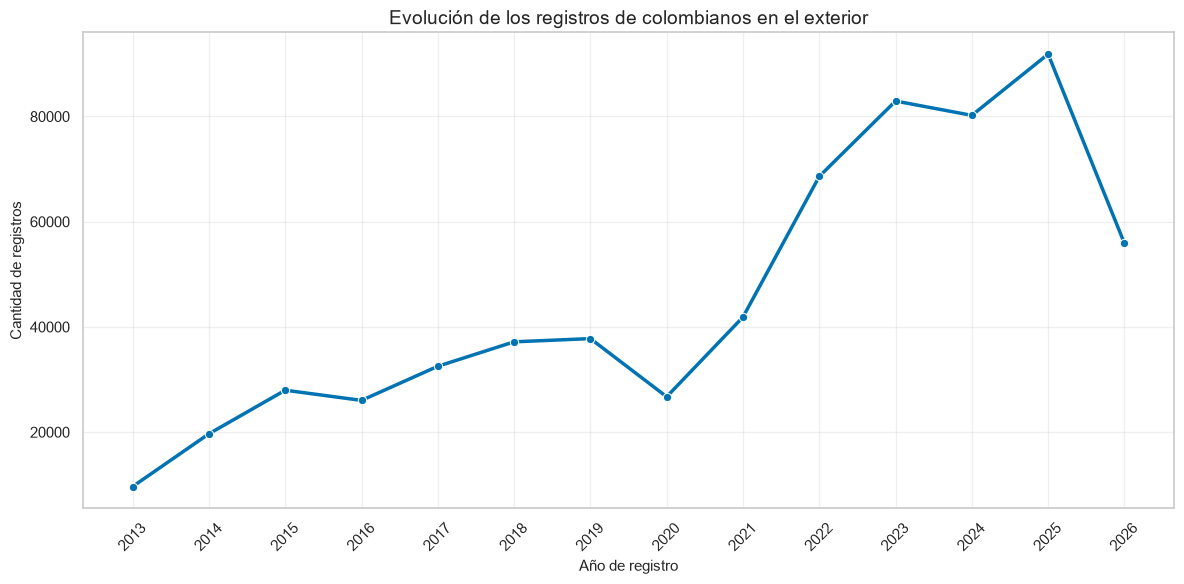

In [34]:
# GRÁFICA 1: EVOLUCIÓN DE LOS REGISTROS POR AÑO

registros_anuales = (
    df_visual.dropna(subset=["Año_Registro"])
    .groupby("Año_Registro")
    .size()
    .sort_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=registros_anuales.index,
    y=registros_anuales.values,
    marker="o",
    linewidth=2.5
)

plt.title("Evolución de los registros de colombianos en el exterior")
plt.xlabel("Año de registro")
plt.ylabel("Cantidad de registros")
plt.xticks(registros_anuales.index, rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## Gráfica 2: Top 10 países con más personas registradas.

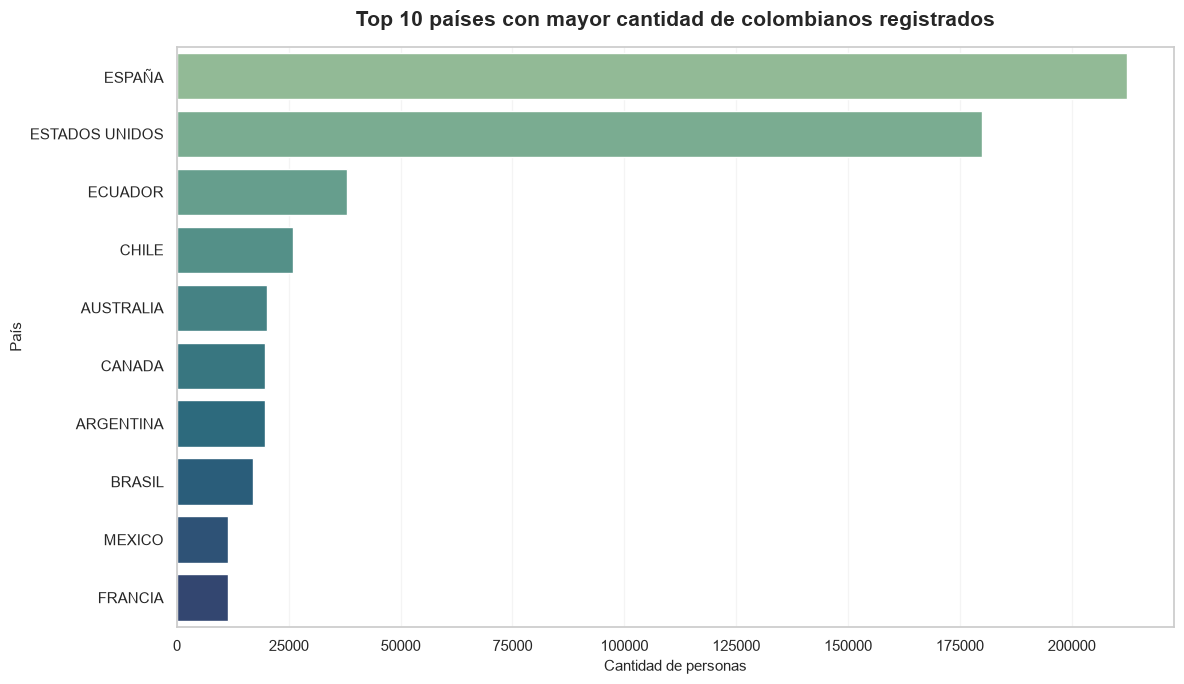

In [35]:
# GRÁFICA 2: TOP 10 PAÍSES CON MÁS PERSONAS REGISTRADAS

top_paises = (
    df_visual.groupby("País")["Total_Personas"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 7))

colores = sns.color_palette("crest", n_colors=10)

sns.barplot(
    x=top_paises.values,
    y=top_paises.index,
    hue=top_paises.index,
    palette=colores,
    legend=False
)

plt.title(
    "Top 10 países con mayor cantidad de colombianos registrados",
    fontsize=15,
    fontweight="bold",
    pad=15
)
plt.xlabel("Cantidad de personas")
plt.ylabel("País")

plt.grid(axis="x", alpha=0.2)
plt.grid(axis="y", visible=False)
plt.tight_layout()

plt.show()

## Gráfica 3: Cantidad de personas por continente

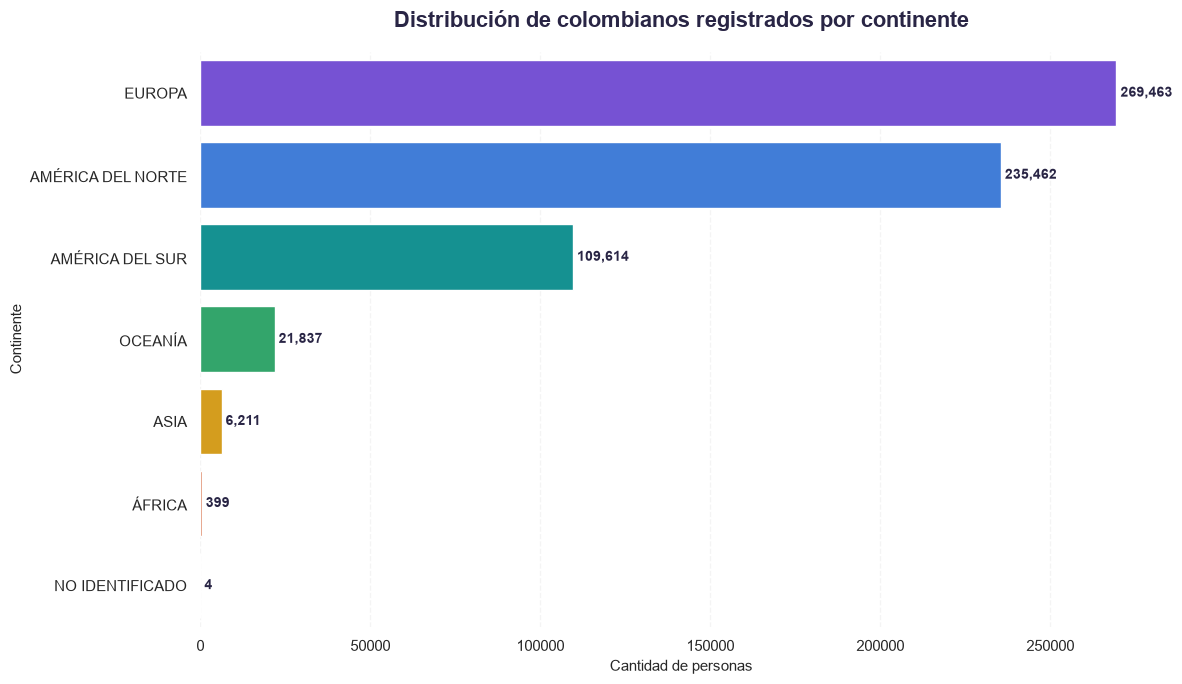

In [36]:
# GRÁFICA 3: CANTIDAD DE PERSONAS POR CONTINENTE

personas_continente = (
    df_visual.groupby("Continente")["Total_Personas"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))

# Paleta de colores vivos
colores = [
    "#6C3CE9",  # Morado
    "#2878F0",  # Azul
    "#00A6A6",  # Turquesa
    "#20B86A",  # Verde
    "#F2A900",  # Amarillo dorado
    "#F06A35",  # Naranja
    "#E84A8A"   # Rosa
]

ax = sns.barplot(
    x=personas_continente.values,
    y=personas_continente.index,
    hue=personas_continente.index,
    palette=colores[:len(personas_continente)],
    legend=False
)

plt.title(
    "Distribución de colombianos registrados por continente",
    fontsize=16,
    fontweight="bold",
    pad=18,
    color="#292545"
)

plt.xlabel("Cantidad de personas", fontsize=11)
plt.ylabel("Continente", fontsize=11)

plt.grid(axis="x", alpha=0.2, linestyle="--")
plt.grid(axis="y", visible=False)

# Etiquetas con cantidades
for i, valor in enumerate(personas_continente.values):
    ax.text(
        valor, i,
        f" {valor:,.0f}",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="#292545"
    )

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

## Gráfica 4: Distribución de personas por grupos de edad.

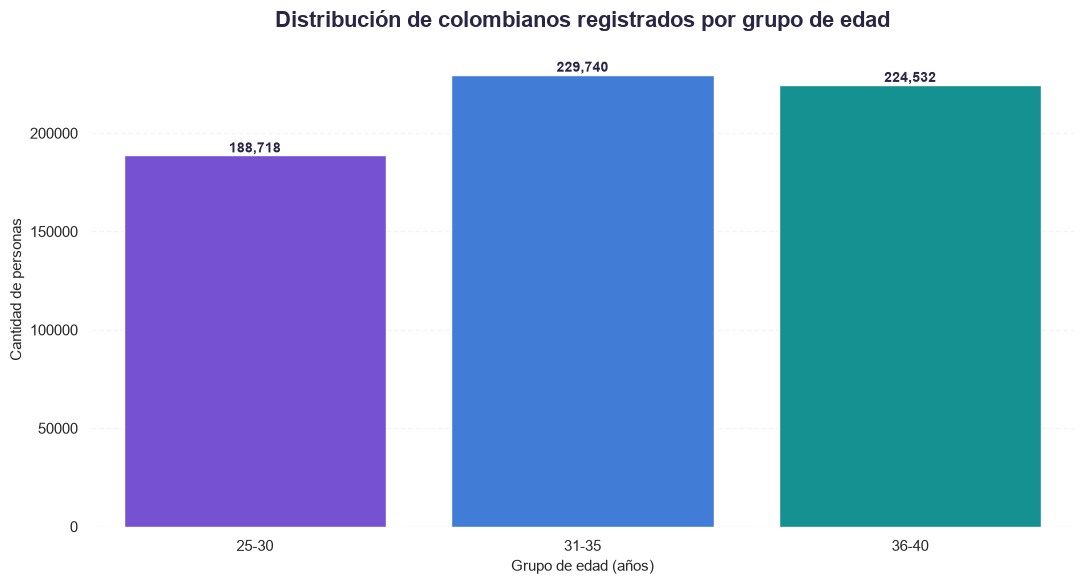

In [37]:
# GRÁFICA 4: DISTRIBUCIÓN POR GRUPOS DE EDAD

orden_edades = ["25-30", "31-35", "36-40"]

personas_edad = (
    df_visual.groupby("Grupo_Edad")["Total_Personas"]
    .sum()
    .reindex(orden_edades)
)

plt.figure(figsize=(11, 6))

colores = ["#6C3CE9", "#2878F0", "#00A6A6"]

ax = sns.barplot(
    x=personas_edad.index,
    y=personas_edad.values,
    hue=personas_edad.index,
    palette=colores,
    legend=False
)

plt.title(
    "Distribución de colombianos registrados por grupo de edad",
    fontsize=16,
    fontweight="bold",
    pad=18,
    color="#292545"
)

plt.xlabel("Grupo de edad (años)", fontsize=11)
plt.ylabel("Cantidad de personas", fontsize=11)

# Mostrar cantidades encima de las barras
for i, valor in enumerate(personas_edad.values):
    ax.text(
        i, valor,
        f"{valor:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#292545"
    )

plt.grid(axis="y", alpha=0.2, linestyle="--")
plt.grid(axis="x", visible=False)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

## Gráfica 5: Relación entre continente y grupo de edad

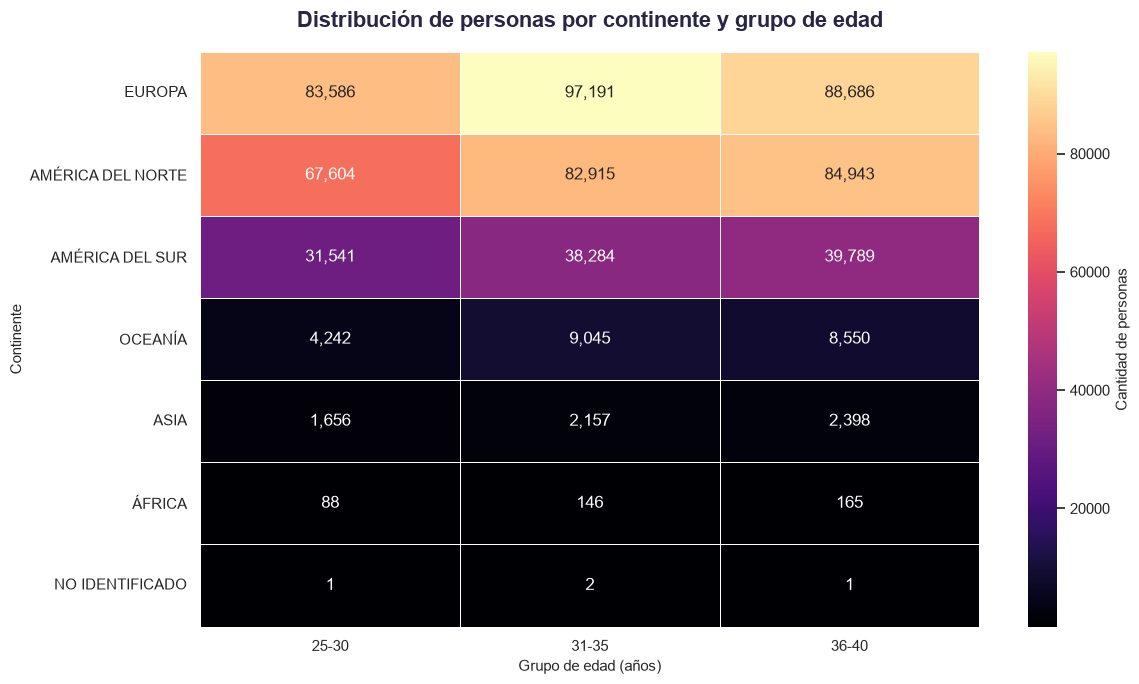

In [38]:
# GRÁFICA 5: CONTINENTE VS. GRUPO DE EDAD

orden_edades = ["25-30", "31-35", "36-40"]

tabla_edad_continente = pd.pivot_table(
    df_visual,
    values="Total_Personas",
    index="Continente",
    columns="Grupo_Edad",
    aggfunc="sum",
    fill_value=0
)

tabla_edad_continente = tabla_edad_continente.reindex(
    columns=orden_edades
)

# Ordenar continentes según el total de personas
tabla_edad_continente = tabla_edad_continente.loc[
    tabla_edad_continente.sum(axis=1).sort_values(ascending=False).index
]

plt.figure(figsize=(12, 7))

sns.heatmap(
    tabla_edad_continente,
    annot=True,
    fmt=",.0f",
    cmap="magma",
    linewidths=0.7,
    linecolor="white",
    cbar_kws={"label": "Cantidad de personas"}
)

plt.title(
    "Distribución de personas por continente y grupo de edad",
    fontsize=16,
    fontweight="bold",
    pad=18,
    color="#292545"
)

plt.xlabel("Grupo de edad (años)", fontsize=11)
plt.ylabel("Continente", fontsize=11)

plt.tight_layout()
plt.show()

## Código – Agregación OLAP

In [39]:
# AGREGACIÓN OLAP 1: AÑO × CONTINENTE × NIVEL ACADÉMICO

olap_anio_continente_nivel = (
    df_visual.dropna(subset=["Año_Registro"])
    .groupby(
        ["Año_Registro", "Continente", "Nivel Académico"],
        as_index=False
    )["Total_Personas"]
    .sum()
    .sort_values(
        ["Año_Registro", "Continente", "Nivel Académico"]
    )
)

print("AGREGACIÓN OLAP 1")
print("Año × Continente × Nivel Académico")
print("Total de combinaciones:", len(olap_anio_continente_nivel))

display(olap_anio_continente_nivel.head(15))

AGREGACIÓN OLAP 1
Año × Continente × Nivel Académico
Total de combinaciones: 788


,Año_Registro,Continente,Nivel Académico,Total_Personas
0,2013.0,AMÉRICA DEL NORTE,(NO REGISTRA),1
1,2013.0,AMÉRICA DEL NORTE,BACHILLERATO,1064
2,2013.0,AMÉRICA DEL NORTE,DOCTORADO,56
3,2013.0,AMÉRICA DEL NORTE,ESPECIALIZACIÓN,43
4,2013.0,AMÉRICA DEL NORTE,MAESTRÍA,190
5,2013.0,AMÉRICA DEL NORTE,NINGUNO,54
6,2013.0,AMÉRICA DEL NORTE,PRIMARIA,45
7,2013.0,AMÉRICA DEL NORTE,PROFESIONAL,1265
8,2013.0,AMÉRICA DEL NORTE,SIN INFORMACIÓN,63
9,2013.0,AMÉRICA DEL NORTE,TECNOLÓGICA,114


## Agregación OLAP 2: Grupo de edad × Continente × Sexo

In [40]:
# AGREGACIÓN OLAP 2: GRUPO DE EDAD × CONTINENTE × SEXO

olap_edad_continente_sexo = (
    df_visual
    .groupby(
        ["Grupo_Edad", "Continente", "Sexo"],
        as_index=False
    )["Total_Personas"]
    .sum()
    .sort_values(
        ["Grupo_Edad", "Continente", "Sexo"]
    )
)

print("AGREGACIÓN OLAP 2")
print("Grupo de edad × Continente × Sexo")
print("Total de combinaciones:", len(olap_edad_continente_sexo))

display(olap_edad_continente_sexo.head(20))

AGREGACIÓN OLAP 2
Grupo de edad × Continente × Sexo
Total de combinaciones: 57


,Grupo_Edad,Continente,Sexo,Total_Personas
0,25-30,AMÉRICA DEL NORTE,DESCONOCIDO,14
1,25-30,AMÉRICA DEL NORTE,FEMENINO,34204
2,25-30,AMÉRICA DEL NORTE,MASCULINO,33384
3,25-30,AMÉRICA DEL NORTE,NO_BINARIO,2
4,25-30,AMÉRICA DEL SUR,DESCONOCIDO,11
5,25-30,AMÉRICA DEL SUR,FEMENINO,14357
6,25-30,AMÉRICA DEL SUR,MASCULINO,17173
7,25-30,ASIA,FEMENINO,1003
8,25-30,ASIA,MASCULINO,653
9,25-30,EUROPA,DESCONOCIDO,16


## Guardar las agregaciones

In [41]:
# GUARDAR AGREGACIONES OLAP

import os

# Crear carpeta para las agregaciones
os.makedirs("../Data3/agregaciones_olap", exist_ok=True)

# Guardar primera agregación
olap_anio_continente_nivel.to_csv(
    "../Data3/agregaciones_olap/olap_anio_continente_nivel.csv",
    index=False,
    encoding="utf-8-sig"
)

# Guardar segunda agregación
olap_edad_continente_sexo.to_csv(
    "../Data3/agregaciones_olap/olap_edad_continente_sexo.csv",
    index=False,
    encoding="utf-8-sig"
)

print("AGREGACIONES OLAP GUARDADAS CORRECTAMENTE")
print("1. olap_anio_continente_nivel.csv")
print("2. olap_edad_continente_sexo.csv")

AGREGACIONES OLAP GUARDADAS CORRECTAMENTE
1. olap_anio_continente_nivel.csv
2. olap_edad_continente_sexo.csv


## Machine Learning

Preparación del entorno para trabajar con ello

In [42]:
# FASE 5 - MACHINE LEARNING

%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
# IMPORTAR LIBRERÍAS

import pandas as pd
import numpy as np

import sklearn
from sklearn.model_selection import train_test_split

print("ENTORNO DE MACHINE LEARNING PREPARADO")
print("Versión de Scikit-learn:", sklearn.__version__)

ENTORNO DE MACHINE LEARNING PREPARADO
Versión de Scikit-learn: 1.9.1


## Análisis de variable objetivo

In [44]:
# DISTRIBUCIÓN DE LA VARIABLE OBJETIVO

distribucion_continentes = (
    df_visual.groupby("Continente")["Total_Personas"]
    .sum()
    .sort_values(ascending=False)
)

print("DISTRIBUCIÓN DE PERSONAS POR CONTINENTE")
display(
    distribucion_continentes.to_frame(
        name="Total_Personas"
    )
)

print("\nPORCENTAJE POR CONTINENTE")
porcentajes = (
    distribucion_continentes / distribucion_continentes.sum()
) * 100

display(porcentajes.round(2).to_frame(name="Porcentaje"))

DISTRIBUCIÓN DE PERSONAS POR CONTINENTE


,Total_Personas
Continente,
EUROPA,269463
AMÉRICA DEL NORTE,235462
AMÉRICA DEL SUR,109614
OCEANÍA,21837
ASIA,6211
ÁFRICA,399
NO IDENTIFICADO,4



PORCENTAJE POR CONTINENTE


,Porcentaje
Continente,
EUROPA,41.91
AMÉRICA DEL NORTE,36.62
AMÉRICA DEL SUR,17.05
OCEANÍA,3.40
ASIA,0.97
ÁFRICA,0.06
NO IDENTIFICADO,0.00


## Cantidad de registros por continente

In [45]:
# DISTRIBUCIÓN DE REGISTROS POR CONTINENTE

registros_continente = (
    df_visual["Continente"]
    .value_counts()
)

resumen_continentes = pd.DataFrame({
    "Cantidad_Registros": registros_continente,
    "Cantidad_Personas": df_visual.groupby("Continente")[
        "Total_Personas"
    ].sum()
})

resumen_continentes["Porcentaje_Registros"] = (
    resumen_continentes["Cantidad_Registros"]
    / len(df_visual) * 100
).round(2)

display(
    resumen_continentes.sort_values(
        "Cantidad_Registros",
        ascending=False
    )
)

,Cantidad_Registros,Cantidad_Personas,Porcentaje_Registros
Continente,,,
EUROPA,267551,269463,41.87
AMÉRICA DEL NORTE,234567,235462,36.71
AMÉRICA DEL SUR,108637,109614,17.00
OCEANÍA,21696,21837,3.40
ASIA,6187,6211,0.97
ÁFRICA,399,399,0.06
NO IDENTIFICADO,4,4,0.00


## Preparación de los datos para Machine Learning

In [46]:
# PREPARACIÓN DEL CONJUNTO DE DATOS

# Variables predictoras
columnas_numericas = [
    "Edad (años)",
    "Año_Registro"
]

columnas_categoricas = [
    "Área Conocimiento",
    "Nivel Académico",
    "Estado civil",
    "Sexo",
    "Pertenencia étnica"
]

columnas_modelo = (
    columnas_numericas + columnas_categoricas + ["Continente"]
)

# Excluir registros sin continente identificado
df_ml = df_visual[
    df_visual["Continente"] != "NO IDENTIFICADO"
].copy()

# Excluir registros con valores faltantes en las variables seleccionadas
df_ml = df_ml.dropna(subset=columnas_modelo)

# Separar variables predictoras y objetivo
X = df_ml[columnas_numericas + columnas_categoricas]
y = df_ml["Continente"]

print("CONJUNTO DE DATOS PREPARADO")
print("Total de registros:", f"{len(df_ml):,}")
print("Cantidad de variables predictoras:", X.shape[1])
print("Cantidad de clases:", y.nunique())

print("\nDISTRIBUCIÓN DE CLASES:")
display(y.value_counts().to_frame(name="Registros"))

print("\nVARIABLES PREDICTORAS:")
display(X.head())

CONJUNTO DE DATOS PREPARADO
Total de registros: 638,881
Cantidad de variables predictoras: 7
Cantidad de clases: 6

DISTRIBUCIÓN DE CLASES:


,Registros
Continente,
EUROPA,267541
AMÉRICA DEL NORTE,234447
AMÉRICA DEL SUR,108615
OCEANÍA,21693
ASIA,6186
ÁFRICA,399



VARIABLES PREDICTORAS:


,Edad (años),Año_Registro,Área Conocimiento,Nivel Académico,Estado civil,Sexo,Pertenencia étnica
0,37,2018.0,"ECONOMÍA, ADMINISTRACIÓN CONTADURIA Y AFINES",SIN INFORMACIÓN,DESCONOCIDO,FEMENINO,OTRO
1,32,2018.0,CIENCIAS DE LA EDUCACIÓN,SIN INFORMACIÓN,DESCONOCIDO,MASCULINO,OTRO
2,39,2014.0,NINGUNA,BACHILLERATO,CASADO,MASCULINO,NINGUNA
3,25,2021.0,CIENCIAS SOCIALES Y HUMANAS,SIN INFORMACIÓN,SOLTERO,FEMENINO,OTRO
4,25,2025.0,"CIENCIAS SOCIALES, PERIODISMO E INFORMACIÓN",MAESTRÍA,CASADO,FEMENINO,NINGUNA


## Dividir los datos en entrenamiento y prueba

In [47]:
# DIVISIÓN DE DATOS: ENTRENAMIENTO Y PRUEBA

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("DIVISIÓN DE DATOS COMPLETADA")
print("--------------------------------")
print("Registros totales:", f"{len(X):,}")
print("Entrenamiento:", f"{len(X_train):,}")
print("Prueba:", f"{len(X_test):,}")

print("\nDISTRIBUCIÓN EN ENTRENAMIENTO:")
display(y_train.value_counts().to_frame(name="Registros"))

print("\nDISTRIBUCIÓN EN PRUEBA:")
display(y_test.value_counts().to_frame(name="Registros"))

DIVISIÓN DE DATOS COMPLETADA
--------------------------------
Registros totales: 638,881
Entrenamiento: 511,104
Prueba: 127,777

DISTRIBUCIÓN EN ENTRENAMIENTO:


,Registros
Continente,
EUROPA,214033
AMÉRICA DEL NORTE,187557
AMÉRICA DEL SUR,86892
OCEANÍA,17354
ASIA,4949
ÁFRICA,319



DISTRIBUCIÓN EN PRUEBA:


,Registros
Continente,
EUROPA,53508
AMÉRICA DEL NORTE,46890
AMÉRICA DEL SUR,21723
OCEANÍA,4339
ASIA,1237
ÁFRICA,80


## Preparar los datos para los modelos

In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), columnas_numericas),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), columnas_categoricas)
    ]
)

print("PREPROCESAMIENTO CONFIGURADO")
print("--------------------------------")
print("Variables numéricas:", len(columnas_numericas))
print("Variables categóricas:", len(columnas_categoricas))
print("Total de variables originales:", len(columnas_numericas) + len(columnas_categoricas))

PREPROCESAMIENTO CONFIGURADO
--------------------------------
Variables numéricas: 2
Variables categóricas: 5
Total de variables originales: 7


## Entrenar el modelo base

In [49]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

modelo_base = DummyClassifier(strategy="most_frequent")

modelo_base.fit(X_train, y_train)

predicciones_base = modelo_base.predict(X_test)

accuracy_base = accuracy_score(y_test, predicciones_base)

print("RESULTADOS DEL MODELO BASE")
print("--------------------------------")
print("Accuracy:", round(accuracy_base, 4))

print("\nREPORTE DE CLASIFICACIÓN:")
print(classification_report(y_test, predicciones_base, zero_division=0))

RESULTADOS DEL MODELO BASE
--------------------------------
Accuracy: 0.4188

REPORTE DE CLASIFICACIÓN:
                   precision    recall  f1-score   support

AMÉRICA DEL NORTE       0.00      0.00      0.00     46890
  AMÉRICA DEL SUR       0.00      0.00      0.00     21723
             ASIA       0.00      0.00      0.00      1237
           EUROPA       0.42      1.00      0.59     53508
          OCEANÍA       0.00      0.00      0.00      4339
           ÁFRICA       0.00      0.00      0.00        80

         accuracy                           0.42    127777
        macro avg       0.07      0.17      0.10    127777
     weighted avg       0.18      0.42      0.25    127777



## Entrenar el árbol de decisión

In [50]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

modelo_arbol = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("clasificador", DecisionTreeClassifier(
        max_depth=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ))
])

modelo_arbol.fit(X_train, y_train)

predicciones_arbol = modelo_arbol.predict(X_test)

accuracy_arbol = accuracy_score(y_test, predicciones_arbol)

print("RESULTADOS DEL ÁRBOL DE DECISIÓN")
print("--------------------------------")
print("Accuracy:", round(accuracy_arbol, 4))

print("\nREPORTE DE CLASIFICACIÓN:")
print(classification_report(
    y_test,
    predicciones_arbol,
    zero_division=0
))

RESULTADOS DEL ÁRBOL DE DECISIÓN
--------------------------------
Accuracy: 0.3217

REPORTE DE CLASIFICACIÓN:
                   precision    recall  f1-score   support

AMÉRICA DEL NORTE       0.52      0.31      0.39     46890
  AMÉRICA DEL SUR       0.33      0.44      0.37     21723
             ASIA       0.02      0.24      0.03      1237
           EUROPA       0.55      0.27      0.36     53508
          OCEANÍA       0.11      0.58      0.18      4339
           ÁFRICA       0.00      0.06      0.00        80

         accuracy                           0.32    127777
        macro avg       0.25      0.31      0.22    127777
     weighted avg       0.48      0.32      0.36    127777



## Entrenar Random Forest

In [51]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

modelo_random_forest = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("clasificador", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=10,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

print("Entrenando Random Forest...")

modelo_random_forest.fit(X_train, y_train)

predicciones_rf = modelo_random_forest.predict(X_test)

accuracy_rf = accuracy_score(y_test, predicciones_rf)

print("\nRESULTADOS DE RANDOM FOREST")
print("--------------------------------")
print("Accuracy:", round(accuracy_rf, 4))

print("\nREPORTE DE CLASIFICACIÓN:")
print(classification_report(
    y_test,
    predicciones_rf,
    zero_division=0
))

Entrenando Random Forest...

RESULTADOS DE RANDOM FOREST
--------------------------------
Accuracy: 0.3458

REPORTE DE CLASIFICACIÓN:
                   precision    recall  f1-score   support

AMÉRICA DEL NORTE       0.55      0.30      0.38     46890
  AMÉRICA DEL SUR       0.32      0.53      0.40     21723
             ASIA       0.02      0.19      0.04      1237
           EUROPA       0.55      0.29      0.38     53508
          OCEANÍA       0.12      0.66      0.20      4339
           ÁFRICA       0.00      0.11      0.00        80

         accuracy                           0.35    127777
        macro avg       0.26      0.35      0.24    127777
     weighted avg       0.49      0.35      0.38    127777



## Consolidación de las métricas

In [52]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

resultados_modelos = pd.DataFrame([
    {
        "Modelo": "Modelo base",
        "Accuracy": accuracy_score(y_test, predicciones_base),
        "Precision_macro": precision_score(y_test, predicciones_base, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, predicciones_base, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, predicciones_base, average="macro", zero_division=0)
    },
    {
        "Modelo": "Árbol de decisión",
        "Accuracy": accuracy_score(y_test, predicciones_arbol),
        "Precision_macro": precision_score(y_test, predicciones_arbol, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, predicciones_arbol, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, predicciones_arbol, average="macro", zero_division=0)
    },
    {
        "Modelo": "Random Forest",
        "Accuracy": accuracy_score(y_test, predicciones_rf),
        "Precision_macro": precision_score(y_test, predicciones_rf, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, predicciones_rf, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, predicciones_rf, average="macro", zero_division=0)
    }
])

print("COMPARACIÓN GENERAL DE MODELOS")
print("--------------------------------")
display(resultados_modelos.round(4))

COMPARACIÓN GENERAL DE MODELOS
--------------------------------


,Modelo,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Modelo base,0.4188,0.0698,0.1667,0.0984
1,Árbol de decisión,0.3217,0.2549,0.3148,0.2230
2,Random Forest,0.3458,0.2596,0.3474,0.2352


## Matriz de confusión

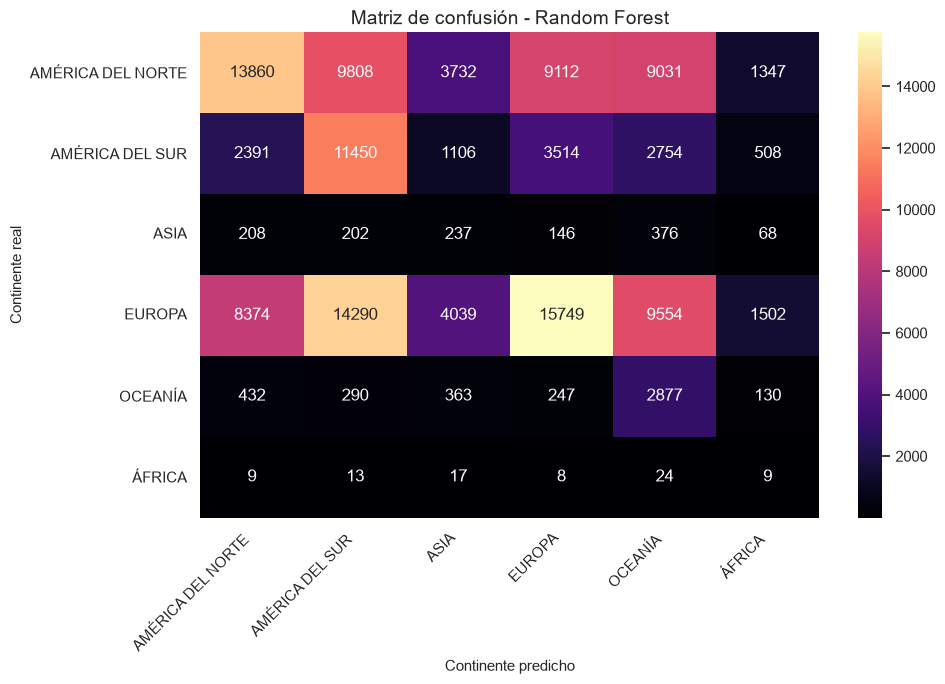

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

matriz_confusion = confusion_matrix(
    y_test,
    predicciones_rf,
    labels=modelo_random_forest.classes_
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    matriz_confusion,
    annot=True,
    fmt="d",
    cmap="magma",
    xticklabels=modelo_random_forest.classes_,
    yticklabels=modelo_random_forest.classes_
)

plt.title("Matriz de confusión - Random Forest")
plt.xlabel("Continente predicho")
plt.ylabel("Continente real")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

## Guardar Random Forest

In [54]:
import os
import joblib

carpeta_modelos = "../models"
os.makedirs(carpeta_modelos, exist_ok=True)

ruta_modelo = os.path.join(
    carpeta_modelos,
    "modelo_random_forest.pkl"
)

joblib.dump(modelo_random_forest, ruta_modelo)

print("MODELO GUARDADO CORRECTAMENTE")
print("--------------------------------")
print("Ruta:", ruta_modelo)
print("Modelo: Random Forest")

MODELO GUARDADO CORRECTAMENTE
--------------------------------
Ruta: ../models\modelo_random_forest.pkl
Modelo: Random Forest


## Comparación del rendimiento de los modelos de Machine Learning, utilizando el F1-score macro

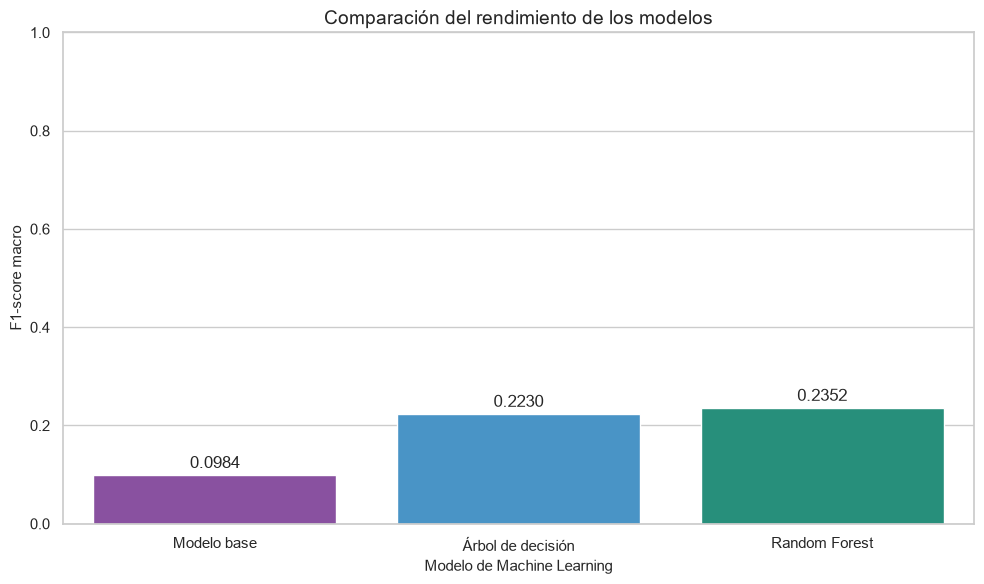

In [55]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=resultados_modelos,
    x="Modelo",
    y="F1_macro",
    hue="Modelo",
    palette=["#8E44AD", "#3498DB", "#16A085"],
    legend=False
)

plt.title("Comparación del rendimiento de los modelos")
plt.xlabel("Modelo de Machine Learning")
plt.ylabel("F1-score macro")
plt.ylim(0, 1)

for i, valor in enumerate(resultados_modelos["F1_macro"]):
    plt.text(i, valor + 0.015, f"{valor:.4f}", ha="center")

plt.tight_layout()
plt.show()

## Análisis de resultados de los modelos de Machine Learning

Se desarrollaron y evaluaron tres modelos de clasificación para predecir el continente de residencia de los colombianos en el exterior, utilizando variables demográficas y académicas.

Inicialmente, se implementó un modelo base que obtuvo un accuracy de 41,88 % y un F1-score macro de 0,0984. Sin embargo, este modelo únicamente identificaba la clase mayoritaria (Europa), por lo que presentó limitaciones para reconocer los demás continentes.

Posteriormente, se entrenó un árbol de decisión, que alcanzó un accuracy de 32,17 % y un F1-score macro de 0,2230. Finalmente, Random Forest obtuvo un accuracy de 34,58 % y un F1-score macro de 0,2352, posicionándose como el modelo con mejor rendimiento equilibrado entre las clases evaluadas.

Se seleccionó Random Forest como modelo definitivo debido a que presentó los mejores resultados en precision macro, recall macro y F1-score macro. No obstante, se identificaron dificultades para clasificar continentes con una cantidad reducida de registros, especialmente África y Asia.

El modelo seleccionado fue almacenado en formato PKL para permitir su reutilización en las siguientes etapas del proyecto, particularmente en el desarrollo del dashboard y la generación del informe automatizado.

## Preparar la conexión con MongoDB

In [56]:
%pip install pymongo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [57]:
try:
    import pymongo
    print("PYMONGO INSTALADO CORRECTAMENTE")
    print("--------------------------------")
    print("Versión:", pymongo.version)

except ImportError:
    print("PyMongo no está instalado.")
    print("Ejecuta: %pip install pymongo")

PYMONGO INSTALADO CORRECTAMENTE
--------------------------------
Versión: 4.20.1


In [58]:
from pymongo import MongoClient
from urllib.parse import quote_plus

MONGODB_URI = input("Pega tu cadena de conexión completa: ").strip()

cliente = MongoClient(
    MONGODB_URI,
    serverSelectionTimeoutMS=10000
)

try:
    cliente.admin.command("ping")
    print("¡CONEXIÓN EXITOSA CON MONGODB ATLAS!")

except Exception as e:
    print("ERROR DE CONEXIÓN")
    print(type(e).__name__, e)

¡CONEXIÓN EXITOSA CON MONGODB ATLAS!


In [59]:
base_datos = cliente["proyecto_bigdata"]

print("Base de datos seleccionada:", base_datos.name)

Base de datos seleccionada: proyecto_bigdata


## Creación de las colecciones

In [60]:
colecciones = [
    "metricas_modelos",
    "hallazgos",
    "recomendaciones"
]

for nombre in colecciones:
    if nombre not in base_datos.list_collection_names():
        base_datos.create_collection(nombre)

print("COLECCIONES CREADAS CORRECTAMENTE")
print("--------------------------------")

for nombre in base_datos.list_collection_names():
    print(nombre)

COLECCIONES CREADAS CORRECTAMENTE
--------------------------------
metricas_modelos
hallazgos
recomendaciones


## Insertar las métricas de los modelos

In [61]:
metricas = [
    {
        "modelo": "DummyClassifier",
        "accuracy": 0.4188,
        "precision_macro": 0.0698,
        "recall_macro": 0.1667,
        "f1_macro": 0.0984
    },
    {
        "modelo": "Decision Tree",
        "accuracy": 0.3217,
        "precision_macro": 0.2549,
        "recall_macro": 0.3148,
        "f1_macro": 0.2230
    },
    {
        "modelo": "Random Forest",
        "accuracy": 0.3458,
        "precision_macro": 0.2596,
        "recall_macro": 0.3474,
        "f1_macro": 0.2352
    }
]

resultado = base_datos["metricas_modelos"].insert_many(metricas)

print("MÉTRICAS INSERTADAS CORRECTAMENTE")
print("--------------------------------")
print("Documentos insertados:", len(resultado.inserted_ids))

MÉTRICAS INSERTADAS CORRECTAMENTE
--------------------------------
Documentos insertados: 3


## Hallazgos del análisis

In [62]:
hallazgos = [
    {
        "numero": 1,
        "titulo": "Predominio de Europa",
        "descripcion": "Europa concentra la mayor cantidad de registros del conjunto de datos.",
        "categoria": "Distribucion geografica"
    },
    {
        "numero": 2,
        "titulo": "Desbalance de clases",
        "descripcion": "Existe una diferencia importante en la cantidad de registros entre los continentes.",
        "categoria": "Calidad de datos"
    },
    {
        "numero": 3,
        "titulo": "Mejor modelo de clasificación",
        "descripcion": "Random Forest obtuvo el mejor resultado de F1 macro con un valor de 0.2352.",
        "categoria": "Machine Learning"
    },
    {
        "numero": 4,
        "titulo": "Limitaciones del modelo base",
        "descripcion": "DummyClassifier obtuvo una exactitud de 0.4188, pero un F1 macro de 0.0984.",
        "categoria": "Evaluacion de modelos"
    },
    {
        "numero": 5,
        "titulo": "Dificultad en clases minoritarias",
        "descripcion": "Asia y África presentan menor representación, lo que dificulta su clasificación.",
        "categoria": "Machine Learning"
    }
]

resultado = base_datos["hallazgos"].insert_many(hallazgos)

print("HALLAZGOS INSERTADOS CORRECTAMENTE")
print("--------------------------------")
print("Documentos insertados:", len(resultado.inserted_ids))

HALLAZGOS INSERTADOS CORRECTAMENTE
--------------------------------
Documentos insertados: 5


## Registro de las recomendaciones

In [63]:
recomendaciones = [
    {
        "numero": 1,
        "titulo": "Mejorar el equilibrio de clases",
        "descripcion": "Aplicar estrategias de balanceo de datos para reducir el efecto del desbalance entre continentes.",
        "prioridad": "Alta"
    },
    {
        "numero": 2,
        "titulo": "Optimizar los modelos de clasificación",
        "descripcion": "Explorar ajustes de hiperparámetros y técnicas de aprendizaje que permitan mejorar el F1 macro.",
        "prioridad": "Alta"
    },
    {
        "numero": 3,
        "titulo": "Ampliar los datos de clases minoritarias",
        "descripcion": "Buscar más registros de continentes como Asia y África para fortalecer el entrenamiento y la evaluación.",
        "prioridad": "Media"
    }
]

resultado = base_datos["recomendaciones"].insert_many(recomendaciones)

print("RECOMENDACIONES INSERTADAS CORRECTAMENTE")
print("--------------------------------")
print("Documentos insertados:", len(resultado.inserted_ids))

RECOMENDACIONES INSERTADAS CORRECTAMENTE
--------------------------------
Documentos insertados: 3


## Consultar los registros almacenados

In [64]:
print("VERIFICACIÓN DE DOCUMENTOS EN MONGODB")
print("-------------------------------------")

for nombre in colecciones:
    cantidad = base_datos[nombre].count_documents({})
    print(f"{nombre}: {cantidad} documentos")

VERIFICACIÓN DE DOCUMENTOS EN MONGODB
-------------------------------------
metricas_modelos: 6 documentos
hallazgos: 10 documentos
recomendaciones: 6 documentos


## Primera consulta: comparación de los modelos

In [65]:
consulta_1 = base_datos["metricas_modelos"].find(
    {},
    {"_id": 0, "modelo": 1, "accuracy": 1, "f1_macro": 1}
).sort("f1_macro", -1)

print("CONSULTA 1: RESULTADOS DE LOS MODELOS")
print("-------------------------------------")

for registro in consulta_1:
    print(registro)

CONSULTA 1: RESULTADOS DE LOS MODELOS
-------------------------------------
{'modelo': 'Random Forest', 'accuracy': 0.3458, 'f1_macro': 0.2352}
{'modelo': 'Random Forest', 'accuracy': 0.3458, 'f1_macro': 0.2352}
{'modelo': 'Decision Tree', 'accuracy': 0.3217, 'f1_macro': 0.223}
{'modelo': 'Decision Tree', 'accuracy': 0.3217, 'f1_macro': 0.223}
{'modelo': 'DummyClassifier', 'accuracy': 0.4188, 'f1_macro': 0.0984}
{'modelo': 'DummyClassifier', 'accuracy': 0.4188, 'f1_macro': 0.0984}


## Segunda consulta: identificar recomendaciones de alta prioridad

In [66]:
consulta_2 = base_datos["recomendaciones"].find(
    {"prioridad": "Alta"},
    {"_id": 0}
)

print("CONSULTA 2: RECOMENDACIONES DE ALTA PRIORIDAD")
print("---------------------------------------------")

for registro in consulta_2:
    print(registro)

CONSULTA 2: RECOMENDACIONES DE ALTA PRIORIDAD
---------------------------------------------
{'numero': 1, 'titulo': 'Mejorar el equilibrio de clases', 'descripcion': 'Aplicar estrategias de balanceo de datos para reducir el efecto del desbalance entre continentes.', 'prioridad': 'Alta'}
{'numero': 2, 'titulo': 'Optimizar los modelos de clasificación', 'descripcion': 'Explorar ajustes de hiperparámetros y técnicas de aprendizaje que permitan mejorar el F1 macro.', 'prioridad': 'Alta'}
{'numero': 1, 'titulo': 'Mejorar el equilibrio de clases', 'descripcion': 'Aplicar estrategias de balanceo de datos para reducir el efecto del desbalance entre continentes.', 'prioridad': 'Alta'}
{'numero': 2, 'titulo': 'Optimizar los modelos de clasificación', 'descripcion': 'Explorar ajustes de hiperparámetros y técnicas de aprendizaje que permitan mejorar el F1 macro.', 'prioridad': 'Alta'}


## Tercera consulta: consultar los hallazgos de Machine Learning

In [67]:
consulta_3 = base_datos["hallazgos"].find(
    {"categoria": "Machine Learning"},
    {"_id": 0}
)

print("CONSULTA 3: HALLAZGOS DE MACHINE LEARNING")
print("-----------------------------------------")

for registro in consulta_3:
    print(registro)

CONSULTA 3: HALLAZGOS DE MACHINE LEARNING
-----------------------------------------
{'numero': 3, 'titulo': 'Mejor modelo de clasificación', 'descripcion': 'Random Forest obtuvo el mejor resultado de F1 macro con un valor de 0.2352.', 'categoria': 'Machine Learning'}
{'numero': 5, 'titulo': 'Dificultad en clases minoritarias', 'descripcion': 'Asia y África presentan menor representación, lo que dificulta su clasificación.', 'categoria': 'Machine Learning'}
{'numero': 3, 'titulo': 'Mejor modelo de clasificación', 'descripcion': 'Random Forest obtuvo el mejor resultado de F1 macro con un valor de 0.2352.', 'categoria': 'Machine Learning'}
{'numero': 5, 'titulo': 'Dificultad en clases minoritarias', 'descripcion': 'Asia y África presentan menor representación, lo que dificulta su clasificación.', 'categoria': 'Machine Learning'}


In [68]:
import os

print("Carpeta de trabajo actual:")
print(os.getcwd())

Carpeta de trabajo actual:
c:\Users\Mateo\OneDrive\Desktop\big-data\data-library-main\notebooks


In [69]:
import os

ruta_csv = "../Data3/Connacionales_inscritos_en_el_Registro_Ciudadano_en_Línea_20261117.csv"

print("¿Existe el archivo?", os.path.exists(ruta_csv))

¿Existe el archivo? True


In [70]:
import os

ruta_parquet = "../data/processed/connacionales_procesados.parquet"

print("¿Existe el archivo Parquet?", os.path.exists(ruta_parquet))

¿Existe el archivo Parquet? True


In [71]:
import os

ruta_modelo = "../models/modelo_random_forest.pkl"

print("¿Existe el modelo?", os.path.exists(ruta_modelo))

¿Existe el modelo? True


In [72]:
import os

print("¿Existe la carpeta OLAP?", os.path.exists("../Data3/agregaciones_olap"))
print("Archivos encontrados:", os.listdir("../Data3/agregaciones_olap"))

¿Existe la carpeta OLAP? True
Archivos encontrados: ['olap_anio_continente_nivel.csv', 'olap_edad_continente_sexo.csv']


In [73]:
import os

print("¿Existe la carpeta reports?", os.path.exists("../reports"))
print("¿Existe el informe PDF?", os.path.exists("../reports/informe_final_big_data.pdf"))
print("¿Existe la carpeta de gráficas?", os.path.exists("../reports/graficas"))

¿Existe la carpeta reports? True
¿Existe el informe PDF? True
¿Existe la carpeta de gráficas? True


In [74]:
cliente.close()

print("Conexión con MongoDB cerrada correctamente.")

Conexión con MongoDB cerrada correctamente.
